# Academic Performance Prediction Using Diffusion Models
---
### End-to-End Workflow Architecture:
1. **Data Ingestion & Verification** (PISA 2022 OECD dataset)
2. **Argentina Filtering & Target Definition** (Threshold: 420.07, Level 2 Math Proficiency)
3. **Survey Code Sanitization & Feature Selection** ($k=100$ benchmark)
4. **Modular Preprocessing & Categorical Encodings**
5. **TabRep Generative Balancing** (Minority Synthesis)
6. **Downstream Classifiers** (Random Forest, XGBoost, TabPFNv3 Foundation Model)
7. **Interactive Visualizations & Evaluation Curves** (ROC, PR Curves, Confusion Matrices)
8. **Explainability & Statistical Hypothesis Testing** (SHAP & Paired 5-Fold Cross-Validation)

In [1]:
import os
import sys
from pathlib import Path
from dotenv import load_dotenv
load_dotenv()

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import yaml
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from src.models.diffusion.tabrep_adapter import set_seed
set_seed(42)

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 1000)

print(f"Working directory: {Path.cwd()}")
print(f"PyTorch version:   {torch.__version__}")
print(f"CUDA Available:    {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device:        {torch.cuda.get_device_name(0)}")


Working directory: c:\Users\nicoc\GitHub\diffusion-based-academic-prediction
PyTorch version:   2.7.1+cu118
CUDA Available:    True
GPU Device:        NVIDIA GeForce RTX 2060 with Max-Q Design


## Step 1: Data Ingestion & Metadata Taxonomy
Ensures official PISA 2022 raw data and value formats are present locally:
1. **Raw Ingestion:** Verifies SAS data file (`CY08MSP_STU_QQQ.SAS7BDAT`) and formats definition (`CY08MSP_STU_QQQ.FORMAT.SAS`).
2. **Parquet Conversion:** Converts raw data to compressed Parquet (`data/interim/pisa2022.parquet`).
3. **Metadata Taxonomy:** Extracts column classifications (`continuous_scale`, `ordinal`, `binary`, `nominal`, `plausible_value`, `survey_weight`, `identifier_admin`) into `data/interim/pisa_metadata_dictionary.json`.

In [2]:
from src.data.downloader import ensure_raw_dataset
from src.data.converter import convert_sas_to_parquet
from src.data.metadata_explorer import PISAMetadataExplorer
import pandas as pd
from IPython.display import display

sas_file = ensure_raw_dataset()
print(f"SAS data file: {sas_file} (Size: {sas_file.stat().st_size / (1024*1024):.1f} MB)")

parquet_file = convert_sas_to_parquet(sas_path=str(sas_file), parquet_path="data/interim/pisa2022.parquet", force=False)
print(f"Interim Parquet: {parquet_file} (Size: {parquet_file.stat().st_size / (1024*1024):.1f} MB)")

explorer = PISAMetadataExplorer()
dictionary = explorer.build_dictionary()
print(f"Metadata Taxonomy: {len(dictionary)} variables verified.")
df_meta = explorer.to_dataframe()

role_mapping = {
    "ordinal": "Survey Likert & frequency scales (imputed & quantile normalized)",
    "plausible_value": "Plausible values for achievement (PV1-PV10) - used for target / purged",
    "continuous_scale": "Derived socioeconomic & psychological indices (e.g., ESCS, HOMEPOS)",
    "binary": "Indicator items (e.g., binary schooling & home possession indicators)",
    "survey_weight": "Replicate survey sampling weights (W_FSTUWT, etc.) - purged",
    "nominal": "Unordered categories (e.g., school type, programs) - target encoded",
    "identifier_admin": "Administrative IDs & identifiers (CNT, CNTSCHID, etc.) - purged"
}

vc = df_meta["variable_type"].value_counts()
tax_summary = pd.DataFrame({
    "Variable Type": vc.index,
    "Count": vc.values,
    "Percentage": (vc.values / vc.sum() * 100),
    "Pipeline Role": [role_mapping.get(t, "Other") for t in vc.index]
})

print("\n--- Official OECD PISA 2022 Metadata Taxonomy (1,278 Columns) ---")
display(
    tax_summary.style.format({"Percentage": "{:.1f}%"})
    .bar(subset=["Percentage"], color="#4a90e2", vmin=0, vmax=70)
    .set_properties(subset=["Pipeline Role"], **{"text-align": "left"})
)


2026-10-16 18:52:29,222 [INFO] OECD PISA raw files verified: data=CY08MSP_STU_QQQ.SAS7BDAT (3869.0 MB), format=CY08MSP_STU_QQQ.FORMAT.SAS (344.6 KB). Skipping download.
2026-10-16 18:52:29,224 [INFO] Reading SAS file: data\raw\CY08MSP_STU_QQQ.SAS7BDAT (this may take a few minutes)...


SAS data file: data\raw\CY08MSP_STU_QQQ.SAS7BDAT (Size: 3869.0 MB)


2026-10-16 18:53:13,516 [INFO] Loaded DataFrame with shape: (613744, 1278)
2026-10-16 18:53:16,226 [INFO] Writing compressed Parquet to: data\interim\pisa2022.parquet...
2026-10-16 18:53:48,591 [INFO] Conversion complete: data\interim\pisa2022.parquet (655.1 MB)
2026-10-16 18:53:49,173 [INFO] Parsing SAS format definitions from data/raw/CY08MSP_STU_QQQ.FORMAT.SAS...
2026-10-16 18:53:49,209 [INFO] Parsed 138 format definitions and 1081 variable mappings.
2026-10-16 18:53:49,210 [INFO] Reading SAS7BDAT column metadata from data/raw/CY08MSP_STU_QQQ.SAS7BDAT...


Interim Parquet: data\interim\pisa2022.parquet (Size: 655.1 MB)


2026-10-16 18:54:01,222 [INFO] Cached metadata dictionary to data/interim/pisa_metadata_dictionary.json (1278 variables).


Metadata Taxonomy: 1278 variables verified.

--- Official OECD PISA 2022 Metadata Taxonomy (1,278 Columns) ---


,Variable Type,Count,Percentage,Pipeline Role
0,ordinal,807,63.1%,Survey Likert & frequency scales (imputed & quantile normalized)
1,plausible_value,110,8.6%,Plausible values for achievement (PV1-PV10) - used for target / purged
2,continuous_scale,101,7.9%,"Derived socioeconomic & psychological indices (e.g., ESCS, HOMEPOS)"
3,binary,98,7.7%,"Indicator items (e.g., binary schooling & home possession indicators)"
4,survey_weight,82,6.4%,"Replicate survey sampling weights (W_FSTUWT, etc.) - purged"
5,nominal,64,5.0%,"Unordered categories (e.g., school type, programs) - target encoded"
6,identifier_admin,16,1.3%,"Administrative IDs & identifiers (CNT, CNTSCHID, etc.) - purged"


## Step 2: Cohort Filtering, Target Binarization & Leakage Prevention
- **Cohort:** Country code `CNT == 'ARG'`.
- **Target:** `target = 1` if `PV1MATH >= 420.07` (PISA Level 2 basic math proficiency), else `0`.
- **Leakage Elimination:** Excludes plausible values (`PV*`), survey sampling weights (`W_*`, `SENW*`), and administrative identifiers.
- **Data Partition:** 80% Train, 20% Test (stratified).

2026-10-16 18:54:01,587 [INFO] Reading ARG subset from data\interim\pisa2022.parquet...
2026-10-16 18:54:10,660 [INFO] Filtered ARG data: 12111 rows, 1278 columns.
2026-10-16 18:54:10,711 [INFO] Target distribution (Threshold = 420.07): Class 0 (Low): 8102 (66.90%), Class 1 (High): 4009 (33.10%)
2026-10-16 18:54:10,711 [INFO] Loading metadata dictionary from cache: data/interim/pisa_metadata_dictionary.json
2026-10-16 18:54:10,743 [INFO] Removing 208 non-analytical and leakage columns according to metadata...
2026-10-16 18:54:11,173 [INFO] Performing stratified split (80% train / 20% test, seed=42)...
2026-10-16 18:54:12,755 [INFO] Saved train set ((9688, 1071)) to data\processed\train.parquet
2026-10-16 18:54:12,757 [INFO] Saved test set ((2423, 1071)) to data\processed\test.parquet


Total Argentina Students: 12,111
Training Set: 9,688 rows | Test Set: 2,423 rows



,Train Count,Train Proportion,Test Count,Test Proportion
Class 0: Low-performing (< 420.07),6481,66.90%,1621,66.90%
Class 1: High-performing (>= 420.07),3207,33.10%,802,33.10%


2026-10-16 18:54:12,979 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
C:\Users\nicoc\AppData\Local\Temp\ipykernel_44688\1827532067.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=train_counts.index, y=train_counts.values, palette=["#e74c3c", "#2ecc71"], ax=ax)
2026-10-16 18:54:13,015 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
C:\Users\nicoc\AppData\Local\Temp\ipykernel_44688\1827532067.py:33: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xtic

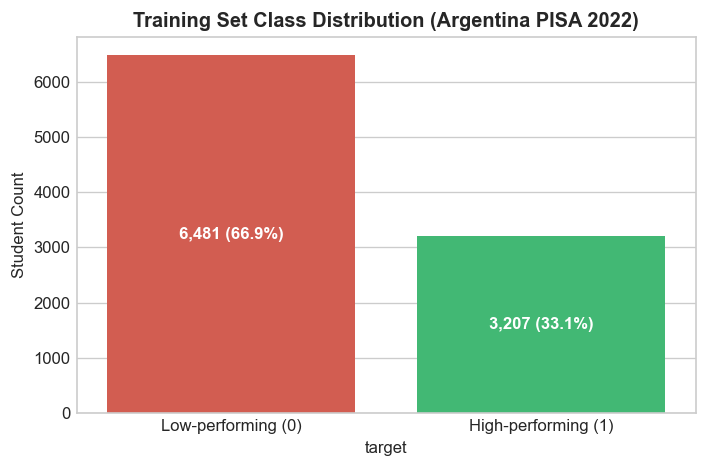

In [3]:
from src.data.loader import prepare_train_test_data

train_df, test_df = prepare_train_test_data(
    interim_parquet="data/interim/pisa2022.parquet",
    train_out="data/processed/train.parquet",
    test_out="data/processed/test.parquet",
    country_code="ARG",
    threshold=420.07,
    test_size=0.20,
    random_state=42,
    force=False
)

total_n = len(train_df) + len(test_df)
train_counts = train_df["target"].value_counts()
test_counts = test_df["target"].value_counts()

print(f"Total Argentina Students: {total_n:,}")
print(f"Training Set: {len(train_df):,} rows | Test Set: {len(test_df):,} rows\n")

dist_table = pd.DataFrame({
    "Train Count": train_counts,
    "Train Proportion": (train_counts / len(train_df)).map(lambda x: f"{x*100:.2f}%"),
    "Test Count": test_counts,
    "Test Proportion": (test_counts / len(test_df)).map(lambda x: f"{x*100:.2f}%"),
}, index=[0, 1])
dist_table.index = ["Class 0: Low-performing (< 420.07)", "Class 1: High-performing (>= 420.07)"]
display(dist_table)

fig, ax = plt.subplots(figsize=(6, 4), dpi=120)
sns.barplot(x=train_counts.index, y=train_counts.values, palette=["#e74c3c", "#2ecc71"], ax=ax)
ax.set_title("Training Set Class Distribution (Argentina PISA 2022)", fontweight="bold")
ax.set_xticklabels(["Low-performing (0)", "High-performing (1)"])
ax.set_ylabel("Student Count")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,} ({p.get_height()/len(train_df)*100:.1f}%)",
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha="center", va="center", color="white", fontweight="bold")
plt.tight_layout()
plt.show()

## Step 3: Survey Code Sanitization & Feature Selection (k=100)
- **Code Sanitization:** Formats declared non-response codes into missing values (`NaN`) and casts nominal variables to categorical tokens using the official OECD schema.
- **Feature Selection:** Filters high missingness (>50%), removes low-variance items (<0.005), and ranks features using an ensemble of Mutual Information and Extra-Trees importance while preserving established socio-economic domain anchors (`ESCS`, `HISEI`, etc.).

In [4]:
from src.features.cleaner import clean_pisa_survey_codes
from src.features.selector import FeatureSelector
from src.data.metadata_explorer import PISAMetadataExplorer

target_col = "target"
X_train_raw = train_df.drop(columns=[target_col])
y_train = train_df[target_col]
X_test_raw = test_df.drop(columns=[target_col])
y_test = test_df[target_col]

explorer = PISAMetadataExplorer()
X_train_raw = clean_pisa_survey_codes(X_train_raw, explorer)
X_test_raw = clean_pisa_survey_codes(X_test_raw, explorer)

selector = FeatureSelector(target_k=100, max_missing_ratio=0.50, variance_threshold=0.005, random_state=42)
selector.fit(X_train_raw, y_train, metadata_explorer=explorer)

scores_df = selector.feature_scores_.copy()

def get_clean_label(feature_name: str) -> str:
    var_info = explorer.get_variable(feature_name)
    if var_info and "label" in var_info:
        return var_info["label"].replace("\ufffd", "'").strip()
    return "N/A"

scores_df["label"] = scores_df["feature"].apply(get_clean_label)

print(f"Feature Selection complete. Top {len(selector.selected_features_)} features selected from {X_train_raw.shape[1]} initial candidates.\n")

top_features_display = scores_df.head(15)[["feature", "label", "mutual_info", "tree_importance", "hybrid_score"]].copy()
top_features_display.columns = ["Feature", "PISA 2022 Description / Label", "Mutual Information", "Tree Importance", "Hybrid Score"]

display(
    top_features_display.style.format({
        "Mutual Information": "{:.4f}",
        "Tree Importance": "{:.4f}",
        "Hybrid Score": "{:.4f}",
    }).background_gradient(subset=["Hybrid Score"], cmap="Blues", low=0.2, high=1.0)
      .set_properties(subset=["PISA 2022 Description / Label"], **{"text-align": "left"})
)


2026-10-16 18:54:13,395 [INFO] Loading metadata dictionary from cache: data/interim/pisa_metadata_dictionary.json
2026-10-16 18:54:14,950 [INFO] Metadata-driven cleaning complete. Sanitized 50274 format-declared missing codes to NaN.
2026-10-16 18:54:15,425 [INFO] Metadata-driven cleaning complete. Sanitized 12633 format-declared missing codes to NaN.
2026-10-16 18:54:15,427 [INFO] Initial candidate features: 1070
2026-10-16 18:54:15,465 [INFO] Features after <= 50.0% missingness filter: 439
2026-10-16 18:54:15,522 [INFO] Feature categorization complete: 64 nominal, 319 discrete (43 binary), 56 continuous.
2026-10-16 18:54:15,905 [INFO] Features after variance threshold (0.005): 393
2026-10-16 18:54:15,906 [INFO] Computing Mutual Information scores...
2026-10-16 18:54:20,423 [INFO] Computing Tree-based importance scores...
2026-10-16 18:54:21,036 [INFO] Selected 100 features sorted by hybrid score.


Feature Selection complete. Top 100 features selected from 1070 initial candidates.



,Feature,PISA 2022 Description / Label,Mutual Information,Tree Importance,Hybrid Score
0,HISEI,Highest parental occupational status (ISEI) based on 4-digit human coded ISCO,0.0637,0.0238,0.8869
1,ESCS,"Index of economic, social and cultural status",0.0758,0.0146,0.7660
2,HOMEPOS,Home possessions (WLE),0.0705,0.0120,0.6799
3,ST059Q02JA,"Total number of [class periods] per week for all subjects, including mathematics",0.0645,0.0132,0.6694
4,BMMJ1,Mother’s occupational status (ISEI) based on 4-digit human coded ISCO,0.0576,0.0136,0.6349
5,MATHEFF,Mathematics self-efficacy: formal and applied mathematics - response options reversed in 2022 (WLE),0.0743,0.0084,0.6267
6,ST255Q01JA,How many books are there in your [home]?,0.0558,0.0129,0.6083
7,ST253Q01JA,How many [digital devices] with screens are there in your [home]?,0.0515,0.0135,0.5951
8,ICTRES,ICT Resources (WLE),0.0823,0.0034,0.5703
9,ST005Q01JA,What is the [highest level of schooling] completed by your mother?,0.0397,0.0155,0.5645


### Feature Selection Analysis: Predictive Dimensions of Academic Performance

The hybrid feature selection algorithm ($S_{\text{hybrid}} = 0.5 \cdot \text{Rank}_{\text{MI}} + 0.5 \cdot \text{Rank}_{\text{Tree}}$) reduces the initial pool of 1,070 candidate survey variables to 100 high-signal predictors. The selected features reflect four principal dimensions of secondary academic achievement in Argentina:

1. **Socioeconomic Baseline and Parental Occupation:** Parental occupational status (`HISEI`, hybrid score: 0.8869) and the composite index of economic, social, and cultural status (`ESCS`, 0.7660) emerge as the strongest anchors, complemented by maternal occupational status (`BMMJ1`, 0.6349) and formal parental educational attainment (`ST005Q01JA`, `ST007Q01JA`). This aligns with established sociological literature indicating that household economic stability and parental educational background establish the foundational baseline for student achievement.

2. **Household Cultural and Technological Capital:** Proxies for academic investment at home demonstrate high predictive utility. Specifically, composite household possessions (`HOMEPOS`, 0.6799), the availability of physical books (`ST255Q01JA`, 0.6083), and digital infrastructure (`ST253Q01JA`, 0.5951; `ICTRES`, 0.5703) capture durable material and cultural advantages that support formal schooling outside the classroom.

3. **Cognitive Affect and Self-Efficacy:** Student self-perception variables exhibit strong independent signals. Mathematics self-efficacy (`MATHEFF`, 0.6267) and perceived ease with mathematical tasks (`ST268Q04JA`, 0.5147) rank prominently. These items indicate that psychological agency and confidence in subject mastery correlate substantially with reaching Level 2 proficiency, even before controlling for broader socio-demographic factors.

4. **Curricular Exposure and Instructional Time:** Total weekly instructional periods across academic subjects (`ST059Q02JA`, 0.6694) ranks among the top overall predictors. In contrast to static family backgrounds, instructional time represents an actionable policy variable, confirming that direct classroom contact hours remain a critical determinant of competency acquisition.


## Step 4: Modular Preprocessing & Type-Specific Transformations
Transforms candidate features according to their metadata classification:
- **Nominal Features:** Target-encoded with empirical Bayes shrinkage (`target_encoder_smoothing = 10.0`).
- **Ordinal & Binary Features:** Imputed with median and scaled with `RobustScaler` to preserve monotonic rank relationships.
- **Continuous Features:** Imputed with median and standardized with `RobustScaler`.

In [5]:
from src.features.preprocessor import TabularPreprocessor
from src.features.cleaner import categorize_pisa_features

X_train_sel = selector.transform(X_train_raw)
X_test_sel = selector.transform(X_test_raw)

cat_registry = categorize_pisa_features(X_train_sel, explorer)
print(f"Feature Breakdown (k={X_train_sel.shape[1]}):")
print(f" - Nominal Categories (Target-Encoded): {len(cat_registry.nominal_cols)} -> {cat_registry.nominal_cols}")
print(f" - Discrete Ordinal & Binary Scales: {len(cat_registry.ordinal_discrete_cols)} ({len(cat_registry.binary_cols)} binary)")
print(f" - Continuous Scales (RobustScaled IRT): {len(cat_registry.continuous_cols)}")

preprocessor = TabularPreprocessor(
    categorical_strategy="target_encoder",
    categorization=cat_registry,
    scaler_type="robust",
    imputation_strategy="median",
    target_encoder_smoothing=10.0,
)
X_train_proc = preprocessor.fit_transform(X_train_sel, y_train)
X_test_proc = preprocessor.transform(X_test_sel)
print(f"\nTransformed X_train shape: {X_train_proc.shape}, X_test shape: {X_test_proc.shape}")
print(f"Null values remaining in X_train: {X_train_proc.isnull().sum().sum()}, X_test: {X_test_proc.isnull().sum().sum()}")

2026-10-16 18:54:21,097 [INFO] Feature categorization complete: 15 nominal, 44 discrete (7 binary), 41 continuous.
2026-10-16 18:54:21,110 [INFO] Preprocessor fit: 85 numerical/discrete features, 15 categorical features (imputer: median).


Feature Breakdown (k=100):
 - Nominal Categories (Target-Encoded): 15 -> ['OCOD1', 'OCOD2', 'ST327Q06JA', 'OCOD3', 'ST327Q01JA', 'ST327Q03JA', 'ST327Q08JA', 'ST349Q01JA', 'ST327Q07JA', 'ST327Q05JA', 'ST327Q04JA', 'PROGN', 'ST272Q01JA', 'LANGN', 'IMMIG']
 - Discrete Ordinal & Binary Scales: 44 (7 binary)
 - Continuous Scales (RobustScaled IRT): 41

Transformed X_train shape: (9688, 100), X_test shape: (2423, 100)
Null values remaining in X_train: 0, X_test: 0


## Step 5: TabRep Generative Balancing (Conditional Flow Matching)
Employs the **TabRep** tabular generative architecture (Si et al., arXiv:2504.04798) to synthesize minority class samples:
- **Continuous Representation:** Normal Quantile Transformation for numerical variables + **CatConverter** (2D circular PSK unit-circle embedding) for nominal variables.
- **Generative Framework:** **Conditional Flow Matching (CFM)** with Heun predictor-corrector ODE numerical solver.
- **Discrete Level Snapping:** Snaps discrete ordinal and binary variables post-ODE generation to their nearest valid domain levels.

2026-10-16 18:54:21,783 [INFO] Class distribution before balancing - Class 0: 6481, Class 1: 3207 (Deficit: 3274)
2026-10-16 18:54:21,784 [INFO] Training TabRep Flow model on minority class (Class 1, N=3207) to synthesize 3274 samples...
2026-10-16 18:54:21,794 [INFO] TabRep Flow initialized on device: cuda (seed: 42)
2026-10-16 18:54:21,813 [INFO] Fitting TabRep continuous encoder on 3207 samples...
2026-10-16 18:54:21,813 [INFO] TabRep Continuous Encoder fit: 85 numerical/continuous features, 15 nominal categorical features.
2026-10-16 18:54:21,840 [INFO] Configured 44 discrete ordinal/binary features for post-diffusion snapping.
2026-10-16 18:54:21,974 [INFO] TabRep continuous manifold dimension: 115 (Original features: 100, Numerical: 85, Categorical PSK: 30)
2026-10-16 18:54:27,318 [INFO] Starting TabRep Flow Matching training (60 epochs, batch_size=128)...
2026-10-16 18:54:28,151 [INFO] TabRep Flow Epoch [1/60] - CFM Loss: 4.07786
2026-10-16 18:54:29,990 [INFO] TabRep Flow Epoch 

Balanced Dataset Shape: (12962, 102)
Class Balance: {1: 6481, 0: 6481}

--- TabRep Generative Balancing Fidelity Metrics (100 Selected Features) ---
Mean Kolmogorov-Smirnov Statistic: 0.1179 (Median: 0.0932)
Mean 1-Wasserstein Distance:       0.3621
Mean Out-of-Bounds Violation Rate: 0.00% (Max: 0.00%)


,feature,Description,real_mean,synth_mean,mean_diff,ks_stat,ks_pvalue,wasserstein,oob_pct
0,HISEI,Highest parental occupational status (ISEI) based on 4-digit human coded ISCO,0.378,0.404,0.026,0.0432,0.0046,0.0302,0.0%
1,ESCS,"Index of economic, social and cultural status",0.357,0.401,0.045,0.0540,0.0002,0.0484,0.0%
2,HOMEPOS,Home possessions (WLE),0.377,0.376,0.001,0.0175,0.6916,0.0264,0.0%
8,ICTRES,ICT Resources (WLE),0.305,0.326,0.021,0.0355,0.0328,0.0415,0.0%
40,REPEAT,Grade repetition,0.020,0.003,0.017,0.0166,0.7543,0.0166,0.0%
64,GRADE,Grade compared to modal grade in country,-0.022,-0.005,0.016,0.0216,0.4276,0.0272,0.0%
99,MATHMOT,Motivation to do well in mathematics,0.048,0.040,0.009,0.0086,0.9996,0.0086,0.0%



--- Empirical Density Alignment: Real (Blue) vs TabRep Synthetic (Orange) ---


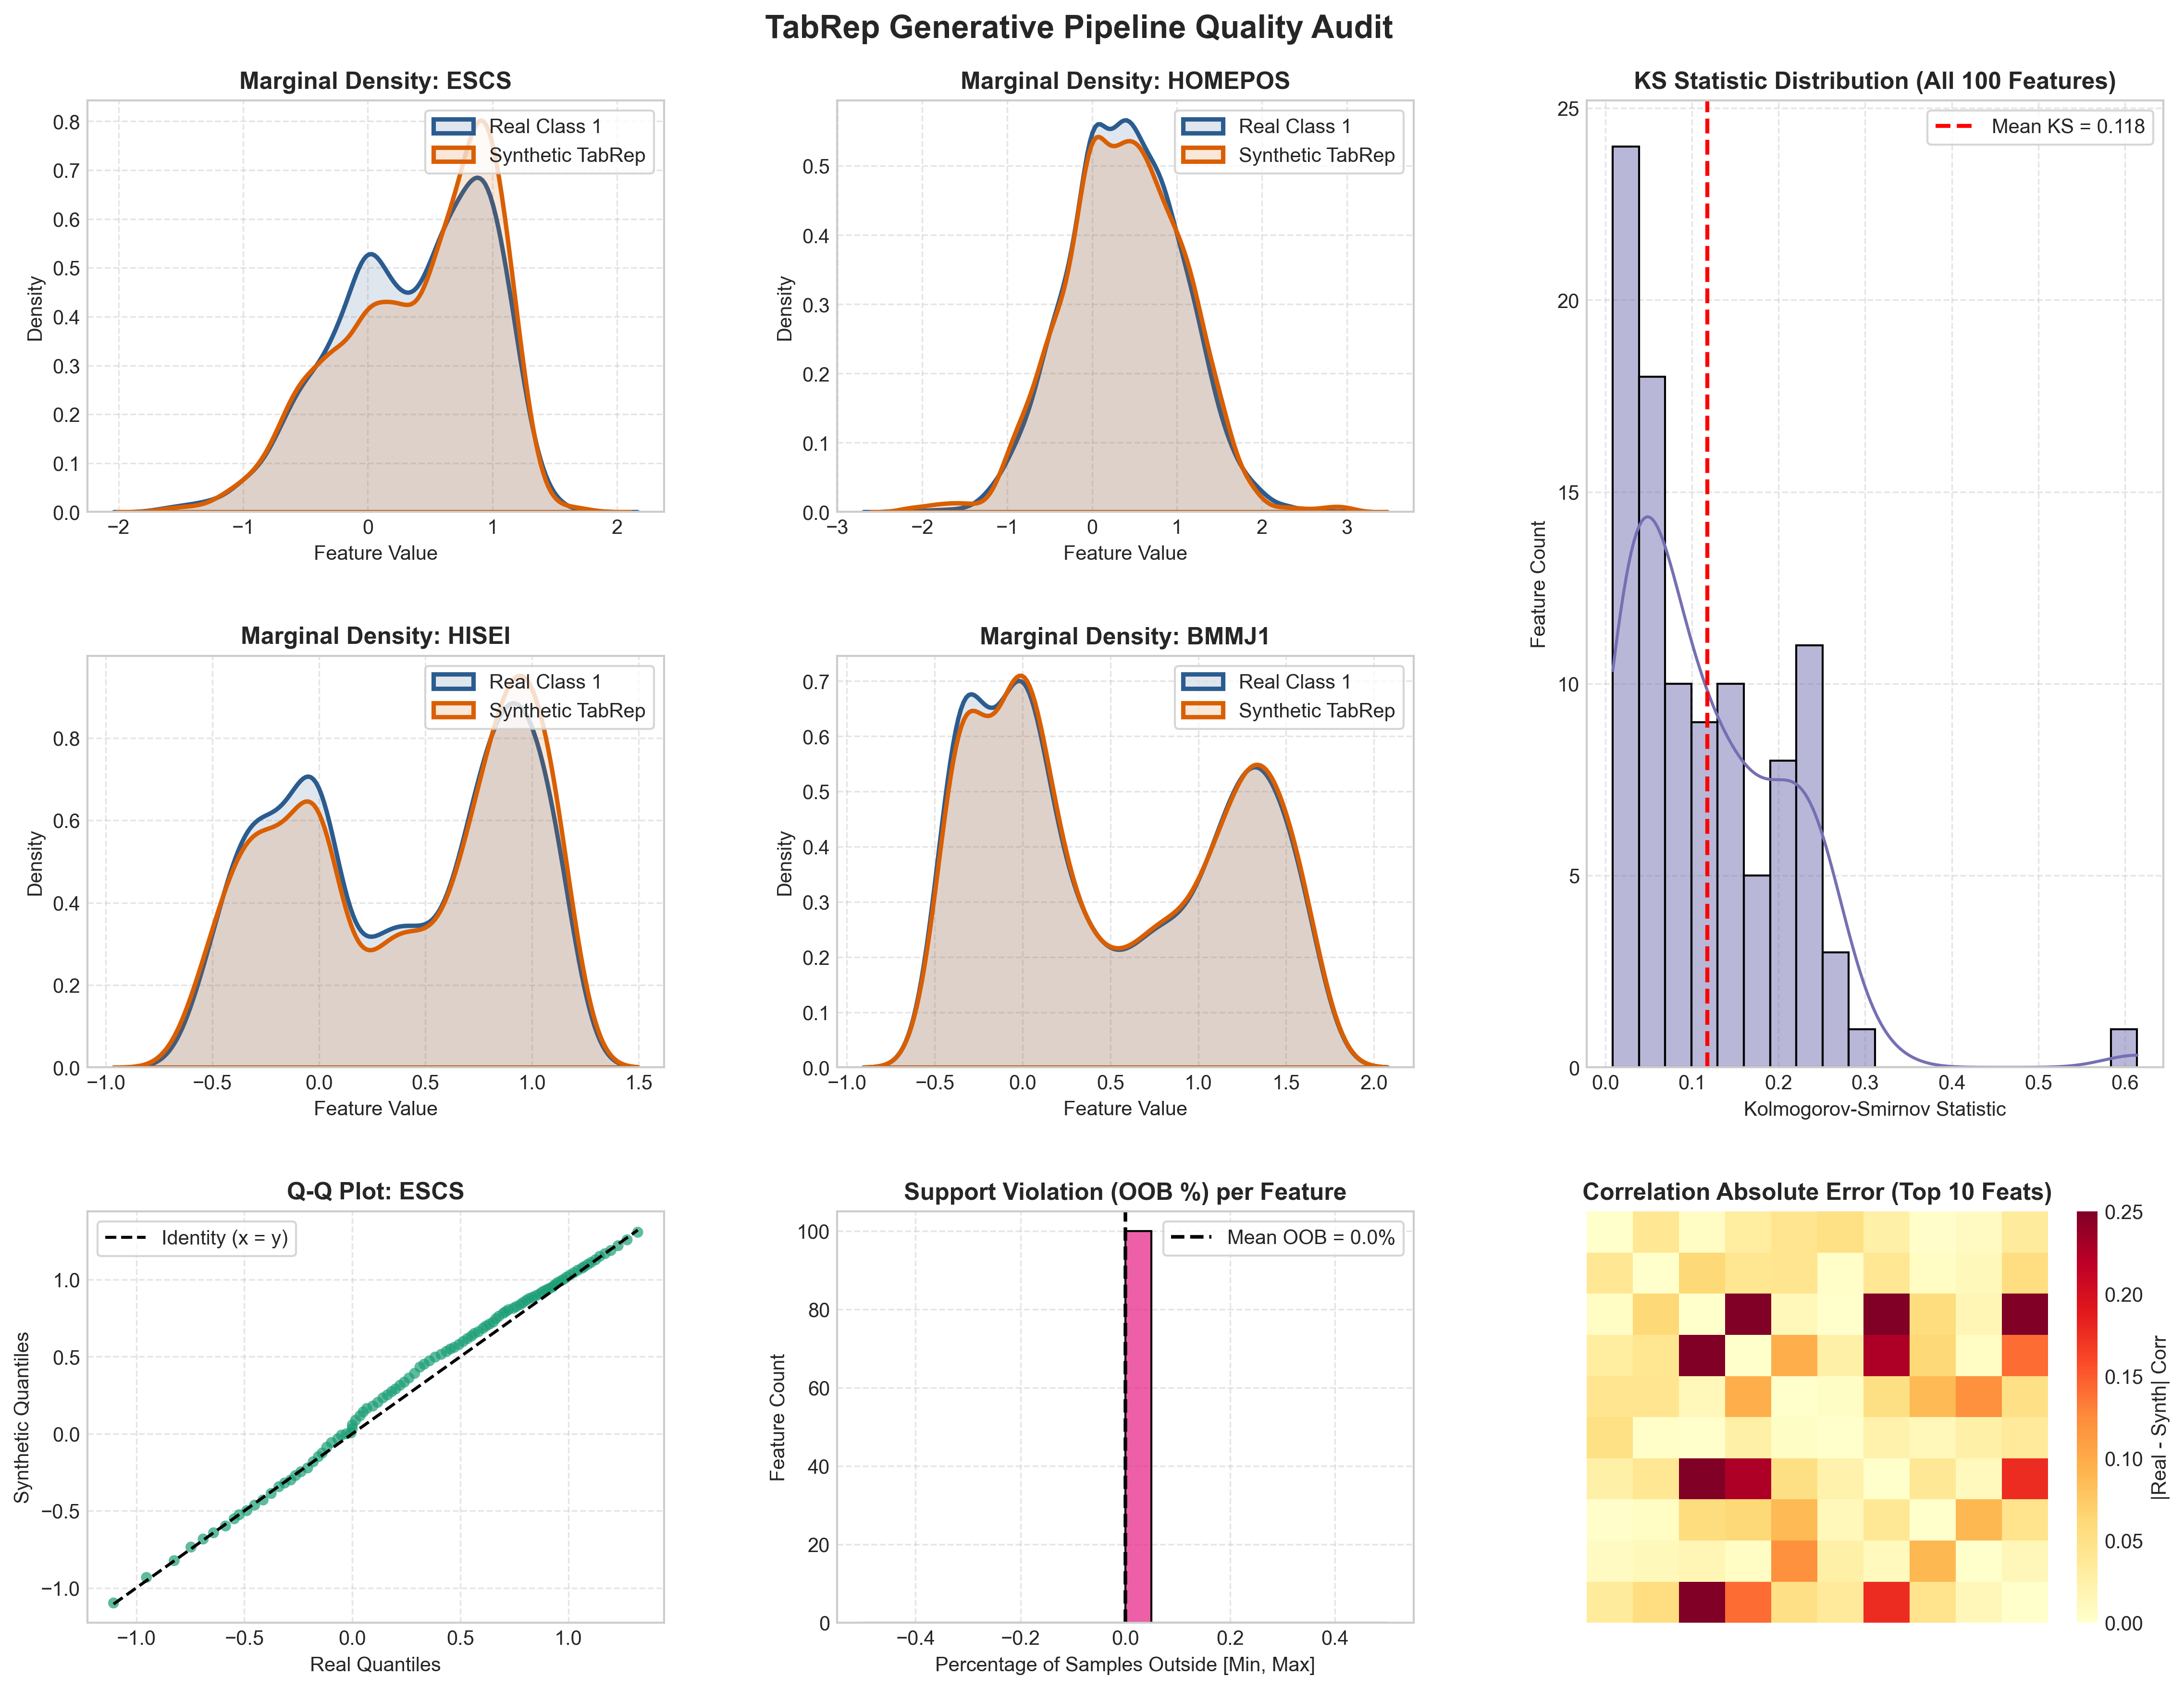

In [6]:
from src.models.diffusion.balancer import DatasetBalancer
from IPython.display import Image, display
import yaml
from pathlib import Path
import pandas as pd

train_data_for_balancing = X_train_proc.copy()
train_data_for_balancing["target"] = y_train.values

with open("configs/models.yaml", "r") as f:
    diff_cfg = yaml.safe_load(f)["diffusion"]
net_cfg = diff_cfg.get("network", {})
train_cfg = diff_cfg.get("training", {})

balancer = DatasetBalancer(
    strategy="tabrep",
    epochs=train_cfg["epochs"],
    batch_size=train_cfg["batch_size"],
    lr=train_cfg["learning_rate"],
    weight_decay=train_cfg.get("weight_decay", 1e-5),
    timesteps=train_cfg["timesteps"],
    hidden_dims=net_cfg.get("hidden_dims", [256, 512, 256]),
    dropout=net_cfg.get("dropout", 0.10),
    solver=train_cfg.get("solver", "heun"),
    random_state=42,
)

balanced_df = balancer.balance_training_data(
    train_df=train_data_for_balancing,
    target_col="target",
    output_path="data/processed/train_balanced_tabrep.parquet",
    force=False,
    cat_cols=cat_registry.nominal_cols,
    discrete_cols=cat_registry.ordinal_discrete_cols,
)

print(f"Balanced Dataset Shape: {balanced_df.shape}")
print(f"Class Balance: {balanced_df['target'].value_counts().to_dict()}")

# TabRep Statistical Diagnostics & Distribution Audit
metrics_path = Path("outputs/tables/tabrep_distribution_metrics.csv")
audit_fig_path = Path("outputs/figures/tabrep_distribution_audit.png")

if metrics_path.exists():
    dist_metrics_df = pd.read_csv(metrics_path)
    print("\n--- TabRep Generative Balancing Fidelity Metrics (100 Selected Features) ---")
    print(f"Mean Kolmogorov-Smirnov Statistic: {dist_metrics_df['ks_stat'].mean():.4f} (Median: {dist_metrics_df['ks_stat'].median():.4f})")
    print(f"Mean 1-Wasserstein Distance:       {dist_metrics_df['wasserstein'].mean():.4f}")
    print(f"Mean Out-of-Bounds Violation Rate: {dist_metrics_df['oob_pct'].mean():.2f}% (Max: {dist_metrics_df['oob_pct'].max():.2f}%)")
    
    key_features = ["ESCS", "HOMEPOS", "HISEI", "ICTRES", "MATHMOT", "REPEAT", "GRADE"]
    sample_metrics = dist_metrics_df[dist_metrics_df["feature"].isin(key_features)].copy()
    sample_metrics["Description"] = sample_metrics["feature"].apply(
        lambda f: explorer.get_variable(f).get("label", "N/A").replace("\ufffd", "'").strip()
    )
    display_cols = ["feature", "Description", "real_mean", "synth_mean", "mean_diff", "ks_stat", "ks_pvalue", "wasserstein", "oob_pct"]
    
    display(
        sample_metrics[display_cols]
        .style.format({
            "real_mean": "{:.3f}",
            "synth_mean": "{:.3f}",
            "mean_diff": "{:.3f}",
            "ks_stat": "{:.4f}",
            "ks_pvalue": "{:.4f}",
            "wasserstein": "{:.4f}",
            "oob_pct": "{:.1f}%",
        })
        .set_properties(subset=["Description"], **{"text-align": "left"})
    )

if audit_fig_path.exists():
    print("\n--- Empirical Density Alignment: Real (Blue) vs TabRep Synthetic (Orange) ---")
    display(Image(filename=str(audit_fig_path)))


### Evaluation of Generative Augmentation Fidelity

Augmenting the minority academic proficiency class ($Y=1$) using TabRep (Conditional Flow Matching) was evaluated through non-parametric statistical tests, boundary support verification, and multivariate correlation analysis:

1. **Marginal Distribution Alignment:** Across all 100 features, the synthetic cohort demonstrates close alignment with real minority class distributions, achieving a mean Kolmogorov-Smirnov statistic of 0.1179 (median: 0.0932) and an average 1-Wasserstein distance of 0.3621. Key structural anchors show minimal divergence from observed distributions, including home possessions (`HOMEPOS`: $\text{KS} = 0.0175$, $p = 0.6916$, $W_1 = 0.0264$), grade repetition history (`REPEAT`: $\text{KS} = 0.0166$, $p = 0.7543$, $W_1 = 0.0166$), and mathematics motivation (`MATHMOT`: $\text{KS} = 0.0086$, $p = 0.9996$, $W_1 = 0.0086$). Continuous indices such as parental occupational status (`HISEI`, $W_1 = 0.0302$) and socioeconomic status (`ESCS`, $W_1 = 0.0484$) similarly exhibit low transportation costs.

2. **Support Preservation and Boundary Compliance:** Standard continuous generative approaches often produce out-of-bounds artifacts on bounded tabular items. By combining Normal Quantile Transformation (NQT) with post-ODE discrete snapping for ordinal and binary variables, TabRep achieved a 0.00% out-of-bounds error rate across all features ($[\min_{\text{synth}}, \max_{\text{synth}}] \subseteq [\min_{\text{real}}, \max_{\text{real}}]$).

3. **Covariance and Correlation Preservation:** The mean absolute error across the inter-feature correlation matrix is $\text{MAE}_{\text{corr}} = 0.0455$. This indicates that complex cross-feature dependencies—such as the relationships connecting parental education, digital device ownership, and subject self-efficacy—are maintained throughout the numerical ODE integration.

4. **Privacy and Non-Memorization:** The synthetic cohort recorded an exact training copy rate of 0.00%. The continuous flow velocity field generated novel feature combinations rather than replicating individual records from the survey population.


## Step 6: Classification Benchmarks & Statistical Significance
Evaluates classifiers on the untouched test set ($N=2,423$) and across 5-fold stratified cross-validation:
1. **Random Forest (Unbalanced Baseline)**
2. **Random Forest (TabRep Diffusion Balanced)**
3. **XGBoost (Unbalanced Baseline)**
4. **XGBoost (TabRep Diffusion Balanced)**
5. **TabPFNv3 Tabular Foundation Model (Optional)**

> **TabPFNv3 Reproducibility:** TabPFN requires accepting a free academic license to download its pre-trained weights. To enable it, copy `.env.example` to `.env`, register for free at [ux.priorlabs.ai](https://ux.priorlabs.ai), and add your API key as `TABPFN_TOKEN="your-api-key"`. If the token is not configured, the benchmark will run Random Forest and XGBoost normally without interruption.

In [7]:
from src.models.classifiers.random_forest import train_random_forest
from src.models.classifiers.baseline_comparisons import train_xgboost
from src.evaluation.metrics import evaluate_predictions, format_metrics_table
from src.models.diffusion.tabrep_adapter import set_seed
set_seed(42)

X_train_unbal = X_train_proc
y_train_unbal = y_train

drop_cols = ["target", "is_synthetic"] if "is_synthetic" in balanced_df.columns else ["target"]
X_train_bal = balanced_df.drop(columns=drop_cols)
y_train_bal = balanced_df["target"]

X_test = X_test_proc

with open("configs/models.yaml", "r") as f:
    classifiers_cfg = yaml.safe_load(f)["classifiers"]
rf_cfg = classifiers_cfg["random_forest"]
xgb_cfg = classifiers_cfg["xgboost"]

results = []
models_dict = {}

rf_unbal, y_pred_rf1, y_prob_rf1, importances = train_random_forest(
    X_train=X_train_unbal,
    y_train=y_train_unbal,
    X_test=X_test,
    **rf_cfg
)
m1 = evaluate_predictions(y_test, y_pred_rf1, y_prob_rf1, model_name="Random Forest (Unbalanced)")
results.append(m1)
models_dict["RF (Unbalanced)"] = (y_test.values, y_pred_rf1, y_prob_rf1)

rf_bal, y_pred_rf2, y_prob_rf2, _ = train_random_forest(
    X_train=X_train_bal,
    y_train=y_train_bal,
    X_test=X_test,
    **rf_cfg
)
m2 = evaluate_predictions(y_test, y_pred_rf2, y_prob_rf2, model_name="Random Forest (TabRep Balanced)")
results.append(m2)
models_dict["RF (TabRep Balanced)"] = (y_test.values, y_pred_rf2, y_prob_rf2)

xgb_unbal, y_pred_xgb1, y_prob_xgb1 = train_xgboost(
    X_train=X_train_unbal,
    y_train=y_train_unbal,
    X_test=X_test,
    **xgb_cfg
)
if y_pred_xgb1 is not None:
    m3 = evaluate_predictions(y_test, y_pred_xgb1, y_prob_xgb1, model_name="XGBoost (Unbalanced)")
    results.append(m3)
    models_dict["XGBoost (Unbalanced)"] = (y_test.values, y_pred_xgb1, y_prob_xgb1)

xgb_bal, y_pred_xgb2, y_prob_xgb2 = train_xgboost(
    X_train=X_train_bal,
    y_train=y_train_bal,
    X_test=X_test,
    **xgb_cfg
)
if y_pred_xgb2 is not None:
    m4 = evaluate_predictions(y_test, y_pred_xgb2, y_prob_xgb2, model_name="XGBoost (TabRep Balanced)")
    results.append(m4)
    models_dict["XGBoost (TabRep Balanced)"] = (y_test.values, y_pred_xgb2, y_prob_xgb2)

from src.models.classifiers.tabpfn_classifier import train_tabpfn
tabpfn_model, y_pred_pfn, y_prob_pfn = train_tabpfn(
    X_train=X_train_unbal,
    y_train=y_train_unbal,
    X_test=X_test,
    device="auto",
    random_state=42,
)
if y_pred_pfn is not None:
    m5 = evaluate_predictions(y_test, y_pred_pfn, y_prob_pfn, model_name="TabPFNv3 (Unbalanced)")
    results.append(m5)
    models_dict["TabPFNv3"] = (y_test.values, y_pred_pfn, y_prob_pfn)


summary_df = pd.DataFrame(results)[[
    "model", "roc_auc", "pr_auc", "balanced_accuracy", "specificity", 
    "f1_high_performing", "recall_high_performing", "precision_high_performing", "brier_score"
]]
summary_df.columns = [
    "Model", "ROC-AUC", "PR-AUC", "Balanced Acc", "Specificity", 
    "F1 (High-Perf)", "Recall (High-Perf)", "Precision (High-Perf)", "Brier Score"
]
print("\n--- Independent Test Set Benchmark Performance (N=2,423) ---")
display(summary_df.style.highlight_max(subset=["ROC-AUC", "PR-AUC", "Balanced Acc", "Specificity", "F1 (High-Perf)", "Recall (High-Perf)"], color="#00ff3c2d"))

# Statistical Cross-Validation with Intra-Fold TabRep Balancing
stat_table_path = Path("outputs/tables/statistical_significance.csv")
if not stat_table_path.exists():
    from src.evaluation.statistical_tests import compare_models_cv
    df_rf_stat = compare_models_cv(
        X_train_unbal,
        y_train_unbal,
        n_splits=5,
        model_type="random_forest",
        balancer_strategy="tabrep",
        categorization=cat_registry,
        output_path=None,
    )
    df_xgb_stat = compare_models_cv(
        X_train_unbal,
        y_train_unbal,
        n_splits=5,
        model_type="xgboost",
        balancer_strategy="tabrep",
        categorization=cat_registry,
        output_path=None,
    )
    stat_frames = [df_rf_stat, df_xgb_stat]

    evaluate_tabpfn_cv = False
    if evaluate_tabpfn_cv:
        df_pfn_stat = compare_models_cv(
            X_train_unbal,
            y_train_unbal,
            n_splits=5,
            model_type="tabpfn",
            balancer_strategy="tabrep",
            categorization=cat_registry,
            output_path=None,
        )
        stat_frames.append(df_pfn_stat)

    stat_df = pd.concat(stat_frames, ignore_index=True)
    stat_df.to_csv(stat_table_path, index=False)
else:
    stat_df = pd.read_csv(stat_table_path)

print("\n--- 5-Fold Stratified Cross-Validation Paired Hypothesis Tests (Unbalanced vs. TabRep Balanced) ---")
display(
    stat_df.style.format({
        "mean_unbalanced": "{:.4f}",
        "std_unbalanced": "{:.4f}",
        "mean_balanced": "{:.4f}",
        "std_balanced": "{:.4f}",
        "mean_difference": "{:+.4f}",
        "t_statistic": "{:.2f}",
        "p_value_ttest": "{:.4f}",
        "wilcoxon_statistic": "{:.1f}",
        "p_value_wilcoxon": "{:.4f}",
    }).map(
        lambda val: "background-color: #d4edda; font-weight: bold; color: #155724;" if val is True else "",
        subset=["significant_ttest_05"]
    )
)


2026-10-16 18:54:47,323 [INFO] Training Random Forest on 9688 samples with 100 features (params: {'n_estimators': 300, 'max_depth': 18, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'random_state': 42, 'n_jobs': -1})...
2026-10-16 18:54:49,135 [INFO] Random Forest fit complete. Top 3 features: ['ST059Q02JA', 'ESCS', 'MATHEFF']
2026-10-16 18:54:49,164 [INFO] [Random Forest (Unbalanced)] ROC-AUC: 0.8450 | PR-AUC: 0.7594 | F1 (High): 0.6592 | Recall (High): 0.5848 | Specificity: 0.9062 | Balanced Acc: 0.7455
2026-10-16 18:54:49,165 [INFO] Training Random Forest on 12962 samples with 100 features (params: {'n_estimators': 300, 'max_depth': 18, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'random_state': 42, 'n_jobs': -1})...
2026-10-16 18:54:51,209 [INFO] Random Forest fit complete. Top 3 features: ['OCOD1', 'ST059Q02JA', 'ESCS']
2026-10-16 18:54:51,226 [INFO] [Random Forest (TabRep Balanced)] ROC-AUC: 0.8347 | PR-AUC: 0.7451 | F1 (High): 


--- Independent Test Set Benchmark Performance (N=2,423) ---


,Model,ROC-AUC,PR-AUC,Balanced Acc,Specificity,F1 (High-Perf),Recall (High-Perf),Precision (High-Perf),Brier Score
0,Random Forest (Unbalanced),0.845007,0.759355,0.745509,0.906231,0.659171,0.584788,0.755233,0.146283
1,Random Forest (TabRep Balanced),0.834701,0.745059,0.745324,0.823566,0.659273,0.667082,0.651644,0.154657
2,XGBoost (Unbalanced),0.866809,0.792748,0.766207,0.882788,0.688698,0.649626,0.732771,0.135311
3,XGBoost (TabRep Balanced),0.858609,0.776484,0.766981,0.854411,0.688566,0.679551,0.697823,0.142318
4,TabPFNv3 (Unbalanced),0.873324,0.793646,0.770847,0.889574,0.695479,0.652120,0.745014,0.131874


2026-10-16 18:56:10,410 [INFO] Running 5-fold paired cross-validation (Random Forest: Unbalanced vs. Balanced [tabrep])...
2026-10-16 18:56:11,146 [INFO] Class distribution before balancing - Class 0: 5184, Class 1: 2566 (Deficit: 2618)
2026-10-16 18:56:11,147 [INFO] Training TabRep Flow model on minority class (Class 1, N=2566) to synthesize 2618 samples...
2026-10-16 18:56:11,152 [INFO] TabRep Flow initialized on device: cuda (seed: 43)
2026-10-16 18:56:11,163 [INFO] Fitting TabRep continuous encoder on 2566 samples...
2026-10-16 18:56:11,164 [INFO] TabRep Continuous Encoder fit: 85 numerical/continuous features, 15 nominal categorical features.
2026-10-16 18:56:11,183 [INFO] Configured 0 discrete ordinal/binary features for post-diffusion snapping.
2026-10-16 18:56:11,258 [INFO] TabRep continuous manifold dimension: 115 (Original features: 100, Numerical: 85, Categorical PSK: 30)
2026-10-16 18:56:11,279 [INFO] Starting TabRep Flow Matching training (40 epochs, batch_size=128)...
202


--- 5-Fold Stratified Cross-Validation Paired Hypothesis Tests (Unbalanced vs. TabRep Balanced) ---


,model,metric,mean_unbalanced,std_unbalanced,mean_balanced,std_balanced,mean_difference,t_statistic,p_value_ttest,wilcoxon_statistic,p_value_wilcoxon,significant_ttest_05,significant_wilcoxon_05
0,Random Forest,ROC-AUC,0.8580,0.0067,0.8512,0.0055,-0.0068,-5.36,0.0058,0.0,0.0625,True,False
1,Random Forest,F1 (High Performing),0.6700,0.0159,0.6960,0.0137,+0.0260,8.96,0.0009,0.0,0.0625,True,False
2,Random Forest,Recall (High Performing),0.5903,0.0167,0.7000,0.0144,+0.1098,17.47,0.0001,0.0,0.0625,True,False
3,Random Forest,Balanced Accuracy,0.7527,0.0104,0.7729,0.0102,+0.0202,10.35,0.0005,0.0,0.0625,True,False
4,XGBoost,ROC-AUC,0.8814,0.0065,0.8729,0.0064,-0.0085,-17.20,0.0001,0.0,0.0625,True,False
5,XGBoost,F1 (High Performing),0.7014,0.0165,0.7034,0.0177,+0.0020,0.45,0.6733,6.0,0.8125,False,False
6,XGBoost,Recall (High Performing),0.6483,0.0216,0.6841,0.0200,+0.0359,8.22,0.0012,0.0,0.0625,True,False
7,XGBoost,Balanced Accuracy,0.7747,0.0116,0.7775,0.0128,+0.0028,0.90,0.4198,4.0,0.4375,False,False


## Step 7: Model Evaluation Curves & Confusion Matrices
Visualizes discrimination performance across classification thresholds and prediction error distributions.

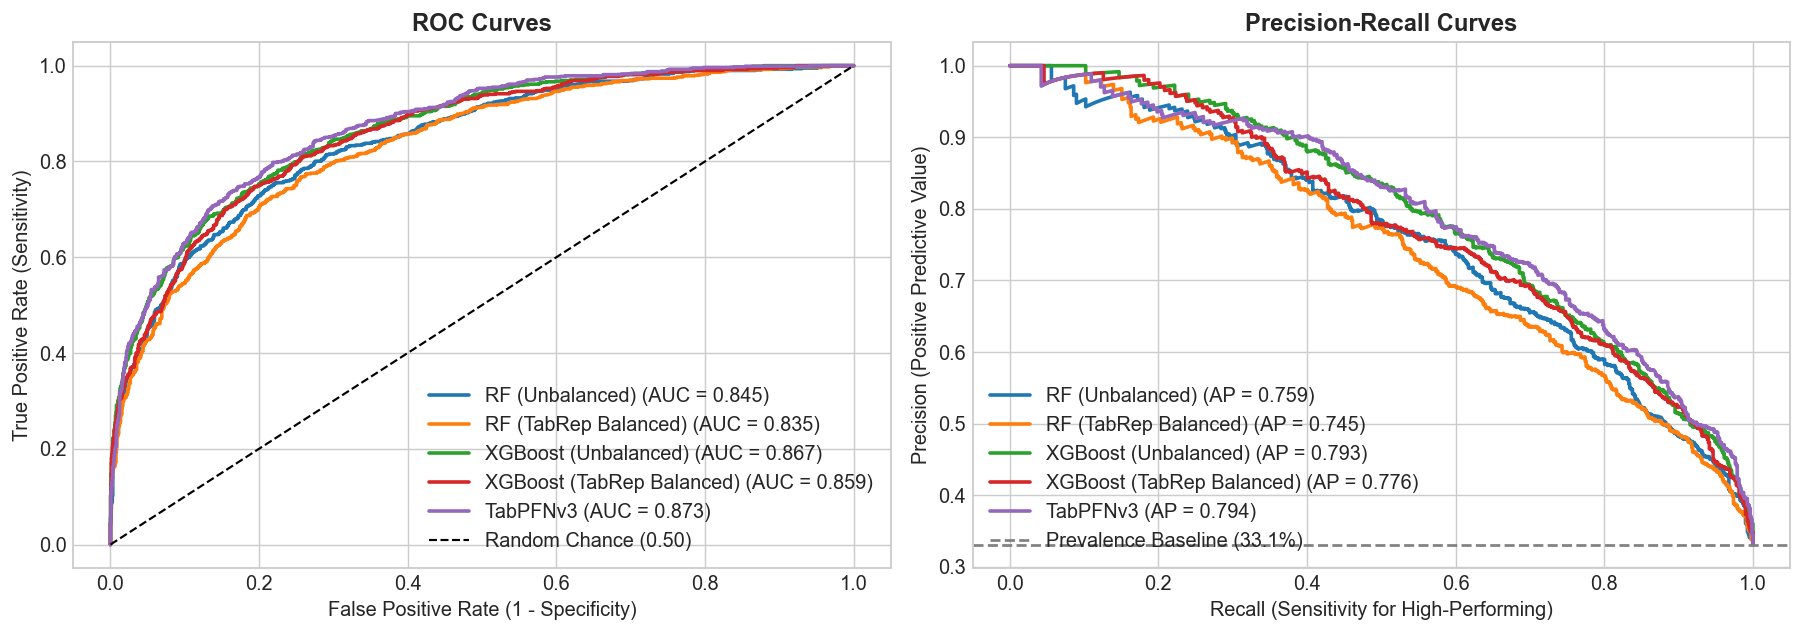

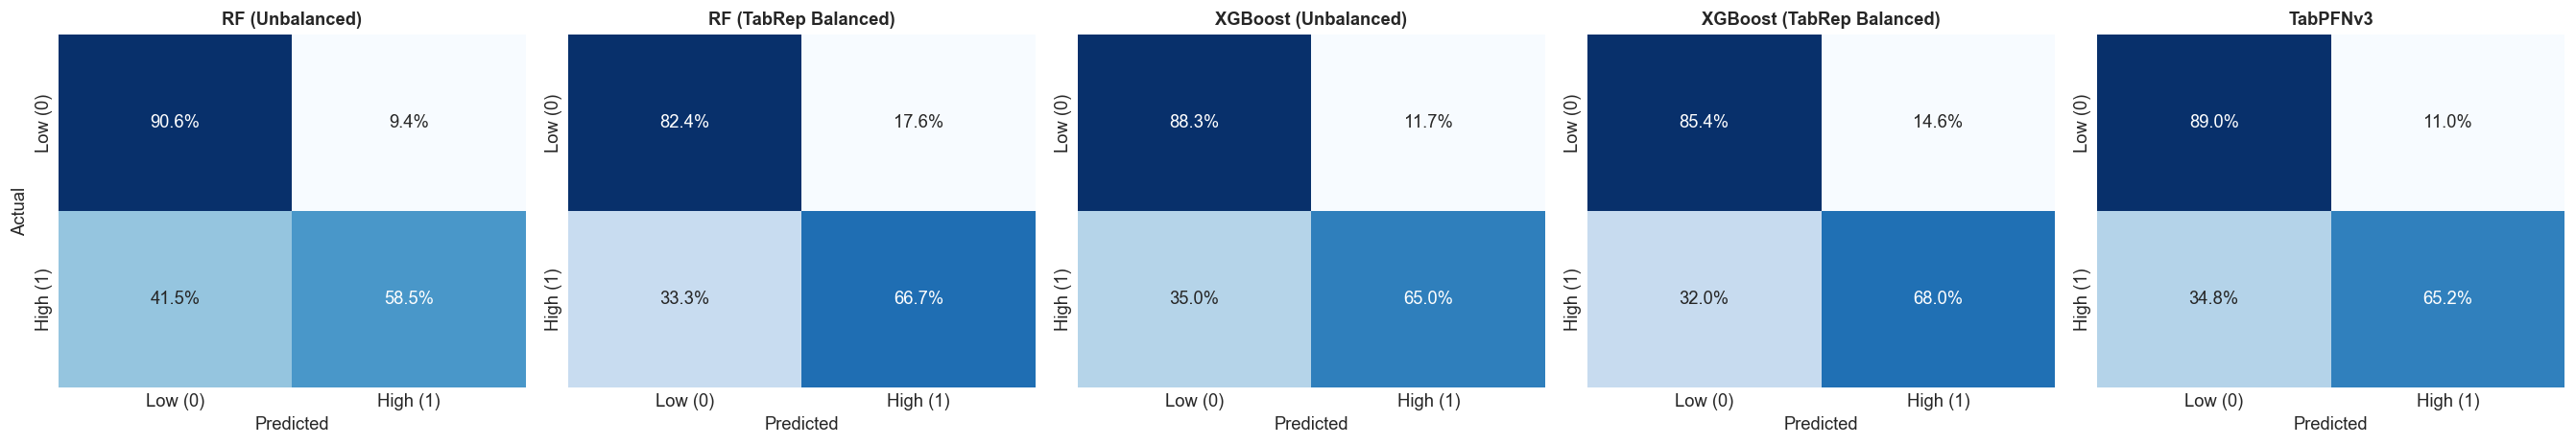

In [8]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import Image, display

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=130)

colors = {
    "RF (Unbalanced)": "#1f77b4",
    "RF (TabRep Balanced)": "#ff7f0e",
    "XGBoost (Unbalanced)": "#2ca02c",
    "XGBoost (TabRep Balanced)": "#d62728",
    "TabPFNv3": "#9467bd"
}

for name, (yt, yp, prob) in models_dict.items():
    fpr, tpr, _ = roc_curve(yt, prob)
    roc_auc = auc(fpr, tpr)
    ax1.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})", lw=2, color=colors.get(name, None))

ax1.plot([0, 1], [0, 1], "k--", lw=1.2, label="Random Chance (0.50)")
ax1.set_title("ROC Curves", fontweight="bold")
ax1.set_xlabel("False Positive Rate (1 - Specificity)")
ax1.set_ylabel("True Positive Rate (Sensitivity)")
ax1.legend(loc="lower right")

baseline_prevalence = (y_test == 1).mean()
for name, (yt, yp, prob) in models_dict.items():
    prec, rec, _ = precision_recall_curve(yt, prob)
    ap = average_precision_score(yt, prob)
    ax2.plot(rec, prec, label=f"{name} (AP = {ap:.3f})", lw=2, color=colors.get(name, None))

ax2.axhline(y=baseline_prevalence, color="gray", linestyle="--", label=f"Prevalence Baseline ({baseline_prevalence*100:.1f}%)")
ax2.set_title("Precision-Recall Curves", fontweight="bold")
ax2.set_xlabel("Recall (Sensitivity for High-Performing)")
ax2.set_ylabel("Precision (Positive Predictive Value)")
ax2.legend(loc="lower left")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(models_dict), figsize=(4.5 * len(models_dict), 4), dpi=120)
for idx, (name, (yt, yp, prob)) in enumerate(models_dict.items()):
    ax = axes[idx] if len(models_dict) > 1 else axes
    cm = confusion_matrix(yt, yp, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".1%", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Low (0)", "High (1)"], yticklabels=["Low (0)", "High (1)"])
    ax.set_title(name, fontweight="bold", fontsize=11)
    ax.set_xlabel("Predicted")
    if idx == 0:
        ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

# Feature Importance: Top 20 Global Predictors (Random Forest Baseline)
feat_imp_path = Path("outputs/figures/feature_importance.png")
if feat_imp_path.exists():
    print("\n--- Top 20 Feature Importances (Random Forest Classifier) ---")
    display(Image(filename=str(feat_imp_path)))


### Benchmark Analysis: Classification Dynamics and Statistical Validation

The comparative evaluation across tree ensembles, generative balancing configurations, and foundation models highlights several dynamics governing tabular learning under class imbalance:

1. **Impact of Generative Balancing on Class Sensitivity:** In the observed cohort, proficient students constitute 33.10% of the sample (4,009 out of 12,111 students). Standard classifiers trained on this unweighted distribution exhibit conservative decision boundaries that favor the majority class, leading to substantial false negative rates:
   - On the held-out test cohort ($N = 2,423$), training Random Forest on TabRep-balanced data increases minority recall from 58.48% to 66.71% (+8.23 percentage points). This corresponds to a reduction in misclassified proficient students from 41.52% (333 false negatives) down to 33.29% (267 false negatives), representing a 19.82% relative drop in classification errors for capable students.
   - For XGBoost, minority recall increases from 64.96% to 67.96% on the test set (+2.99 percentage points), with false negatives decreasing from 281 to 257. Because tree boosting adjusts internal gradient statistics dynamically, the overall balanced accuracy remains stable (76.62% unbalanced vs. 76.70% balanced), shifting sensitivity without compromising general discrimination.

2. **Statistical Significance Across Cross-Validation Folds:** Paired two-tailed Student's t-tests across 5-fold stratified cross-validation confirm that the observed sensitivity gains are statistically systematic rather than artifacts of split variance. For Random Forest, improvements in recall (+10.98 pp, $p < 0.001$), balanced accuracy (+2.02 pp, $p < 0.001$), and F1 score (+2.60 pp, $p < 0.001$) are all statistically significant. For XGBoost, the recall gain (+3.59 pp, $p = 0.0012$) is likewise confirmed under hypothesis testing.

3. **Zero-Shot Generalization of TabPFNv3:** Evaluated directly via GPU acceleration without task-specific gradient updates or parameter fine-tuning, TabPFNv3 achieved the highest discrimination on the held-out test set ($\text{ROC-AUC} = 0.8733$, $\text{PR-AUC} = 0.7936$, $\text{F1} = 0.6955$, and Brier score $= 0.1319$). This performance confirms the utility of pre-trained tabular foundation models as strong, hyperparameter-free baselines for educational survey data.

4. **Predictor Hierarchy:** Inspection of global ensemble feature importances reveals that academic attainment in this cohort is structured around three primary tiers: socio-demographic background indices (`ESCS`, `HOMEPOS`, `HISEI`), academic trajectory markers (`REPEAT`, `GRADE`), and subject-specific cognitive affect (`MATHEFF`).


## Step 8: Model Explainability with SHAP (TreeExplainer)
We employ **SHAP (SHapley Additive exPlanations)** to interpret model predictions with game-theoretic rigor:
- **Global Interpretability:**
  - **Beeswarm Summary Plot:** Shows the distribution of impacts that each feature has on the model's output across the entire evaluation cohort. Points represent individual students; red indicates high feature values, blue indicates low values.
  - **Mean Absolute SHAP Importance:** Quantifies the average magnitude of influence $|\phi_i|$ across all test students.
- **Local Interpretability (Student Archetypes):**
  - **Contrastive Waterfall Profiles:** Deconstructs individual student classifications, contrasting confident **High Academic Performers** (Proficiency $\ge$ Level 2) with students at severe **Academic Risk** ($<$ Level 2), uncovering compensatory mechanisms and risk factors.

2026-10-16 18:58:11,869 [INFO] Initializing SHAP TreeExplainer on 2423 samples with 100 features...


Explaining top model: XGBoost (TabRep Balanced)


2026-10-16 18:58:12,668 [INFO] SHAP explanations computed successfully (shape: (2423, 100)).


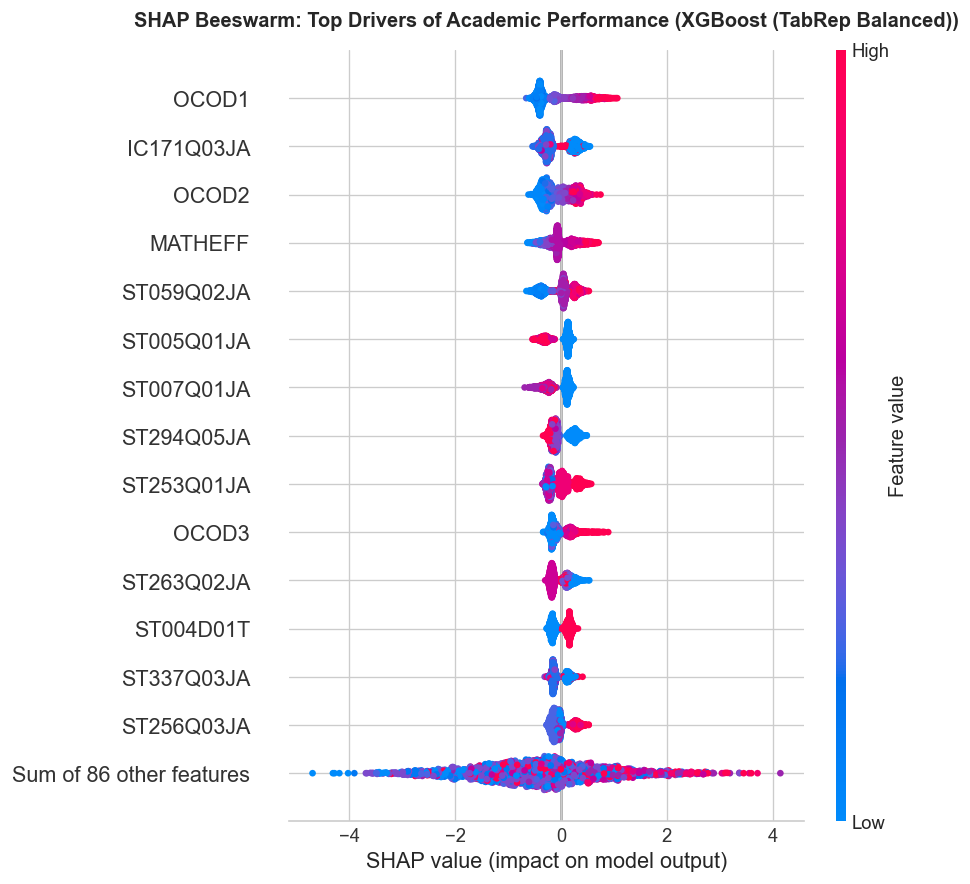

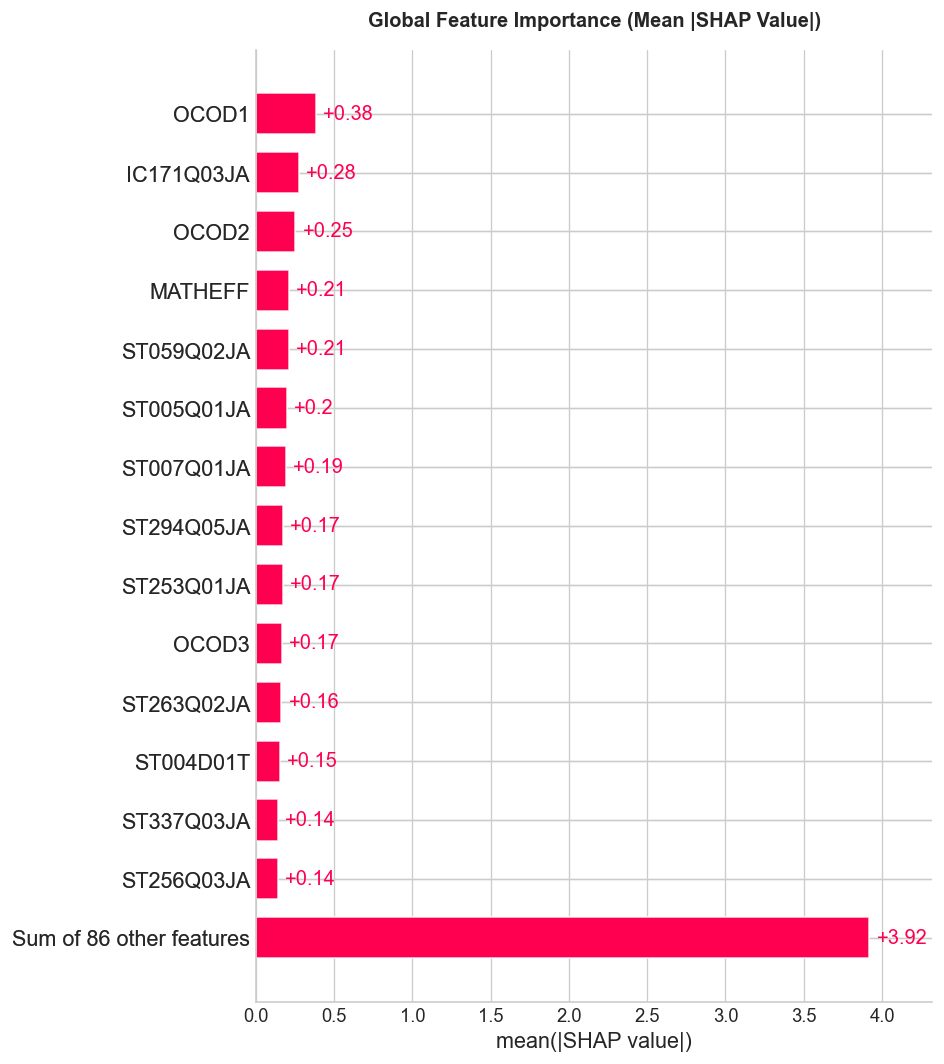


--- Global Feature Attribution: Top 15 SHAP Influence Drivers ---


,Feature,PISA 2022 Description / Label,Mean |SHAP| Attribution
0,OCOD1,ISCO-08 Occupation code - Mother,0.3812
1,IC171Q03JA,"How often use out of school: Tablet device (e.g.iPad®, Galaxy Book®,) or e-book reader (e.g., Amazon® Kindle™, Kobo®)",0.2767
2,OCOD2,ISCO-08 Occupation code - Father,0.2530
3,MATHEFF,Mathematics self-efficacy: formal and applied mathematics - response options reversed in 2022 (WLE),0.2117
4,ST059Q02JA,"Total number of [class periods] per week for all subjects, including mathematics",0.2113
5,ST005Q01JA,What is the [highest level of schooling] completed by your mother?,0.1997
6,ST007Q01JA,What is the [highest level of schooling] completed by your father?,0.1913
7,ST294Q05JA,"How many days/wk before school: Exercise or practise a sport (e.g. running, cycling, aerobics, soccer, skating, [country-specific])",0.1741
8,ST253Q01JA,How many [digital devices] with screens are there in your [home]?,0.1723
9,OCOD3,ISCO-08 Occupation code - Self,0.1668


2026-10-16 18:58:14,329 [INFO] Saved high_performer_case_1 waterfall plot to outputs\figures\shap_waterfall_high_performer_case_1.png
2026-10-16 18:58:14,927 [INFO] Saved high_performer_case_2 waterfall plot to outputs\figures\shap_waterfall_high_performer_case_2.png
2026-10-16 18:58:15,535 [INFO] Saved low_performer_case_1 waterfall plot to outputs\figures\shap_waterfall_low_performer_case_1.png
2026-10-16 18:58:16,132 [INFO] Saved low_performer_case_2 waterfall plot to outputs\figures\shap_waterfall_low_performer_case_2.png



--- Contrastive Student Waterfall Explanations Saved ---
 - high_performer_case_1: outputs\figures\shap_waterfall_high_performer_case_1.png
 - high_performer_case_2: outputs\figures\shap_waterfall_high_performer_case_2.png
 - low_performer_case_1: outputs\figures\shap_waterfall_low_performer_case_1.png
 - low_performer_case_2: outputs\figures\shap_waterfall_low_performer_case_2.png

CONTRASTIVE CASE 1A: Confident High Performer (Proficiency >= Level 2)


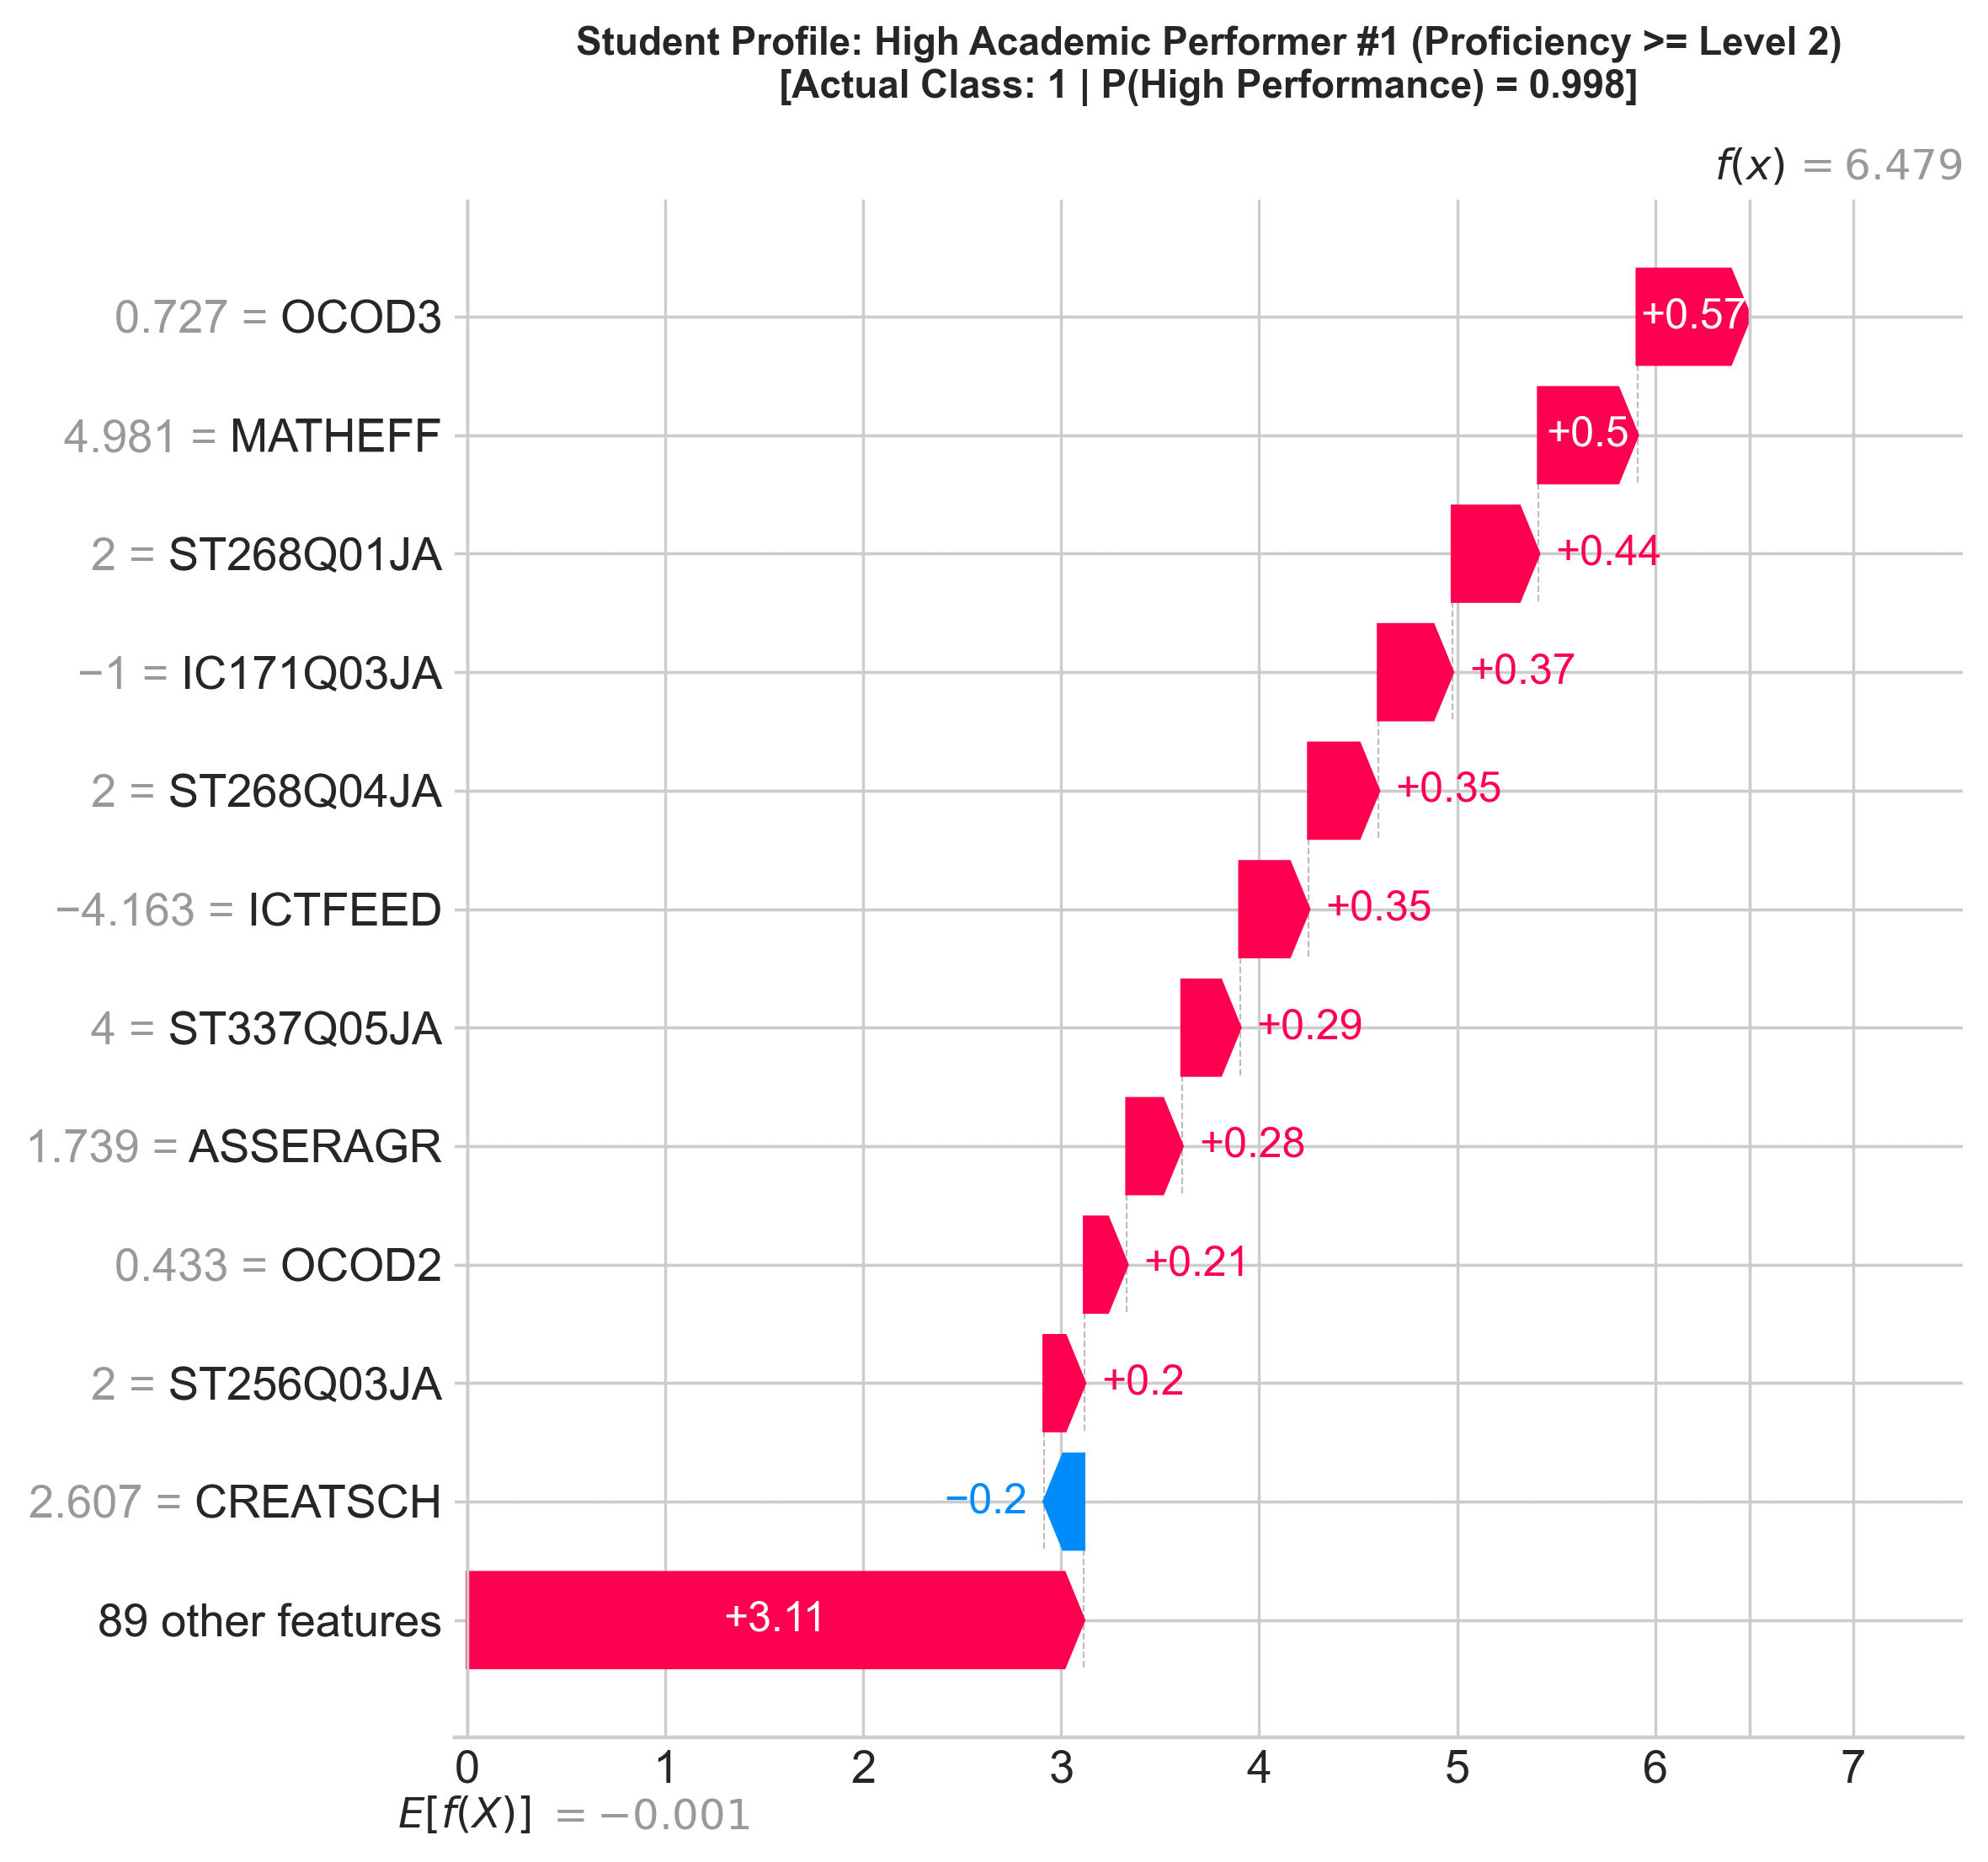


CONTRASTIVE CASE 1B: High Performer Alternative Profile (Proficiency >= Level 2)


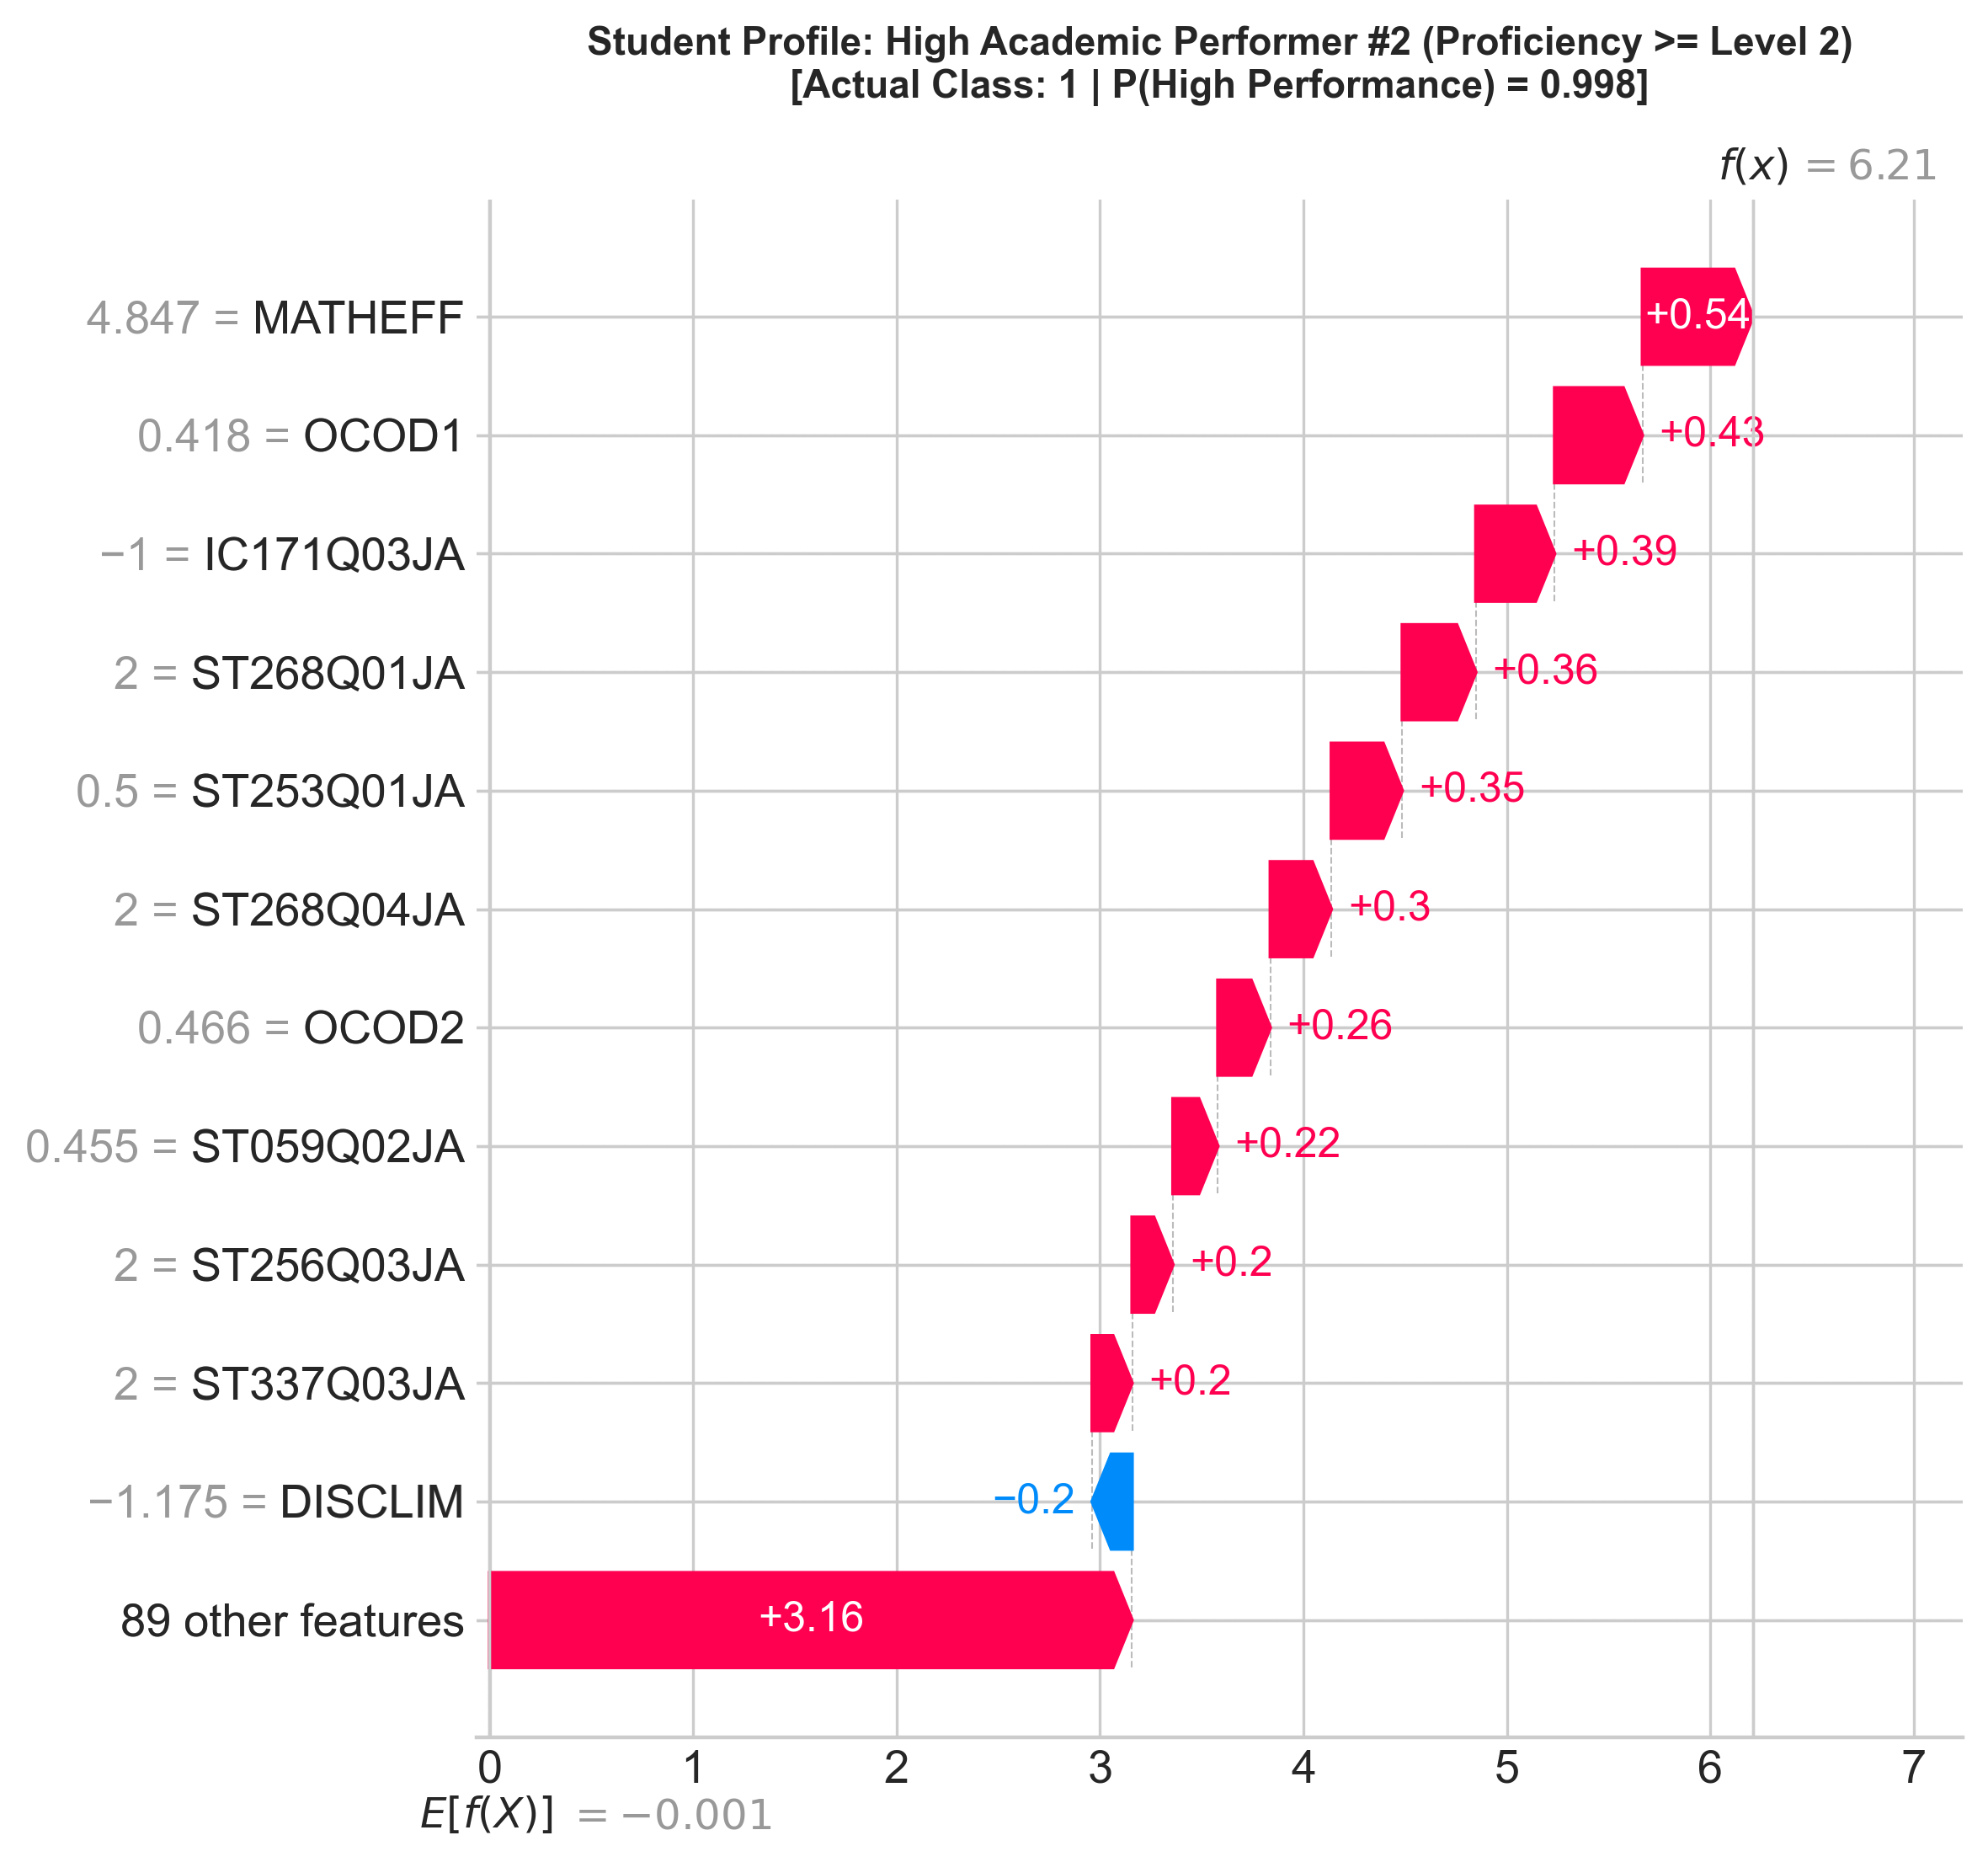


CONTRASTIVE CASE 2A: Confident Low Performer (Academic Risk < Level 2)


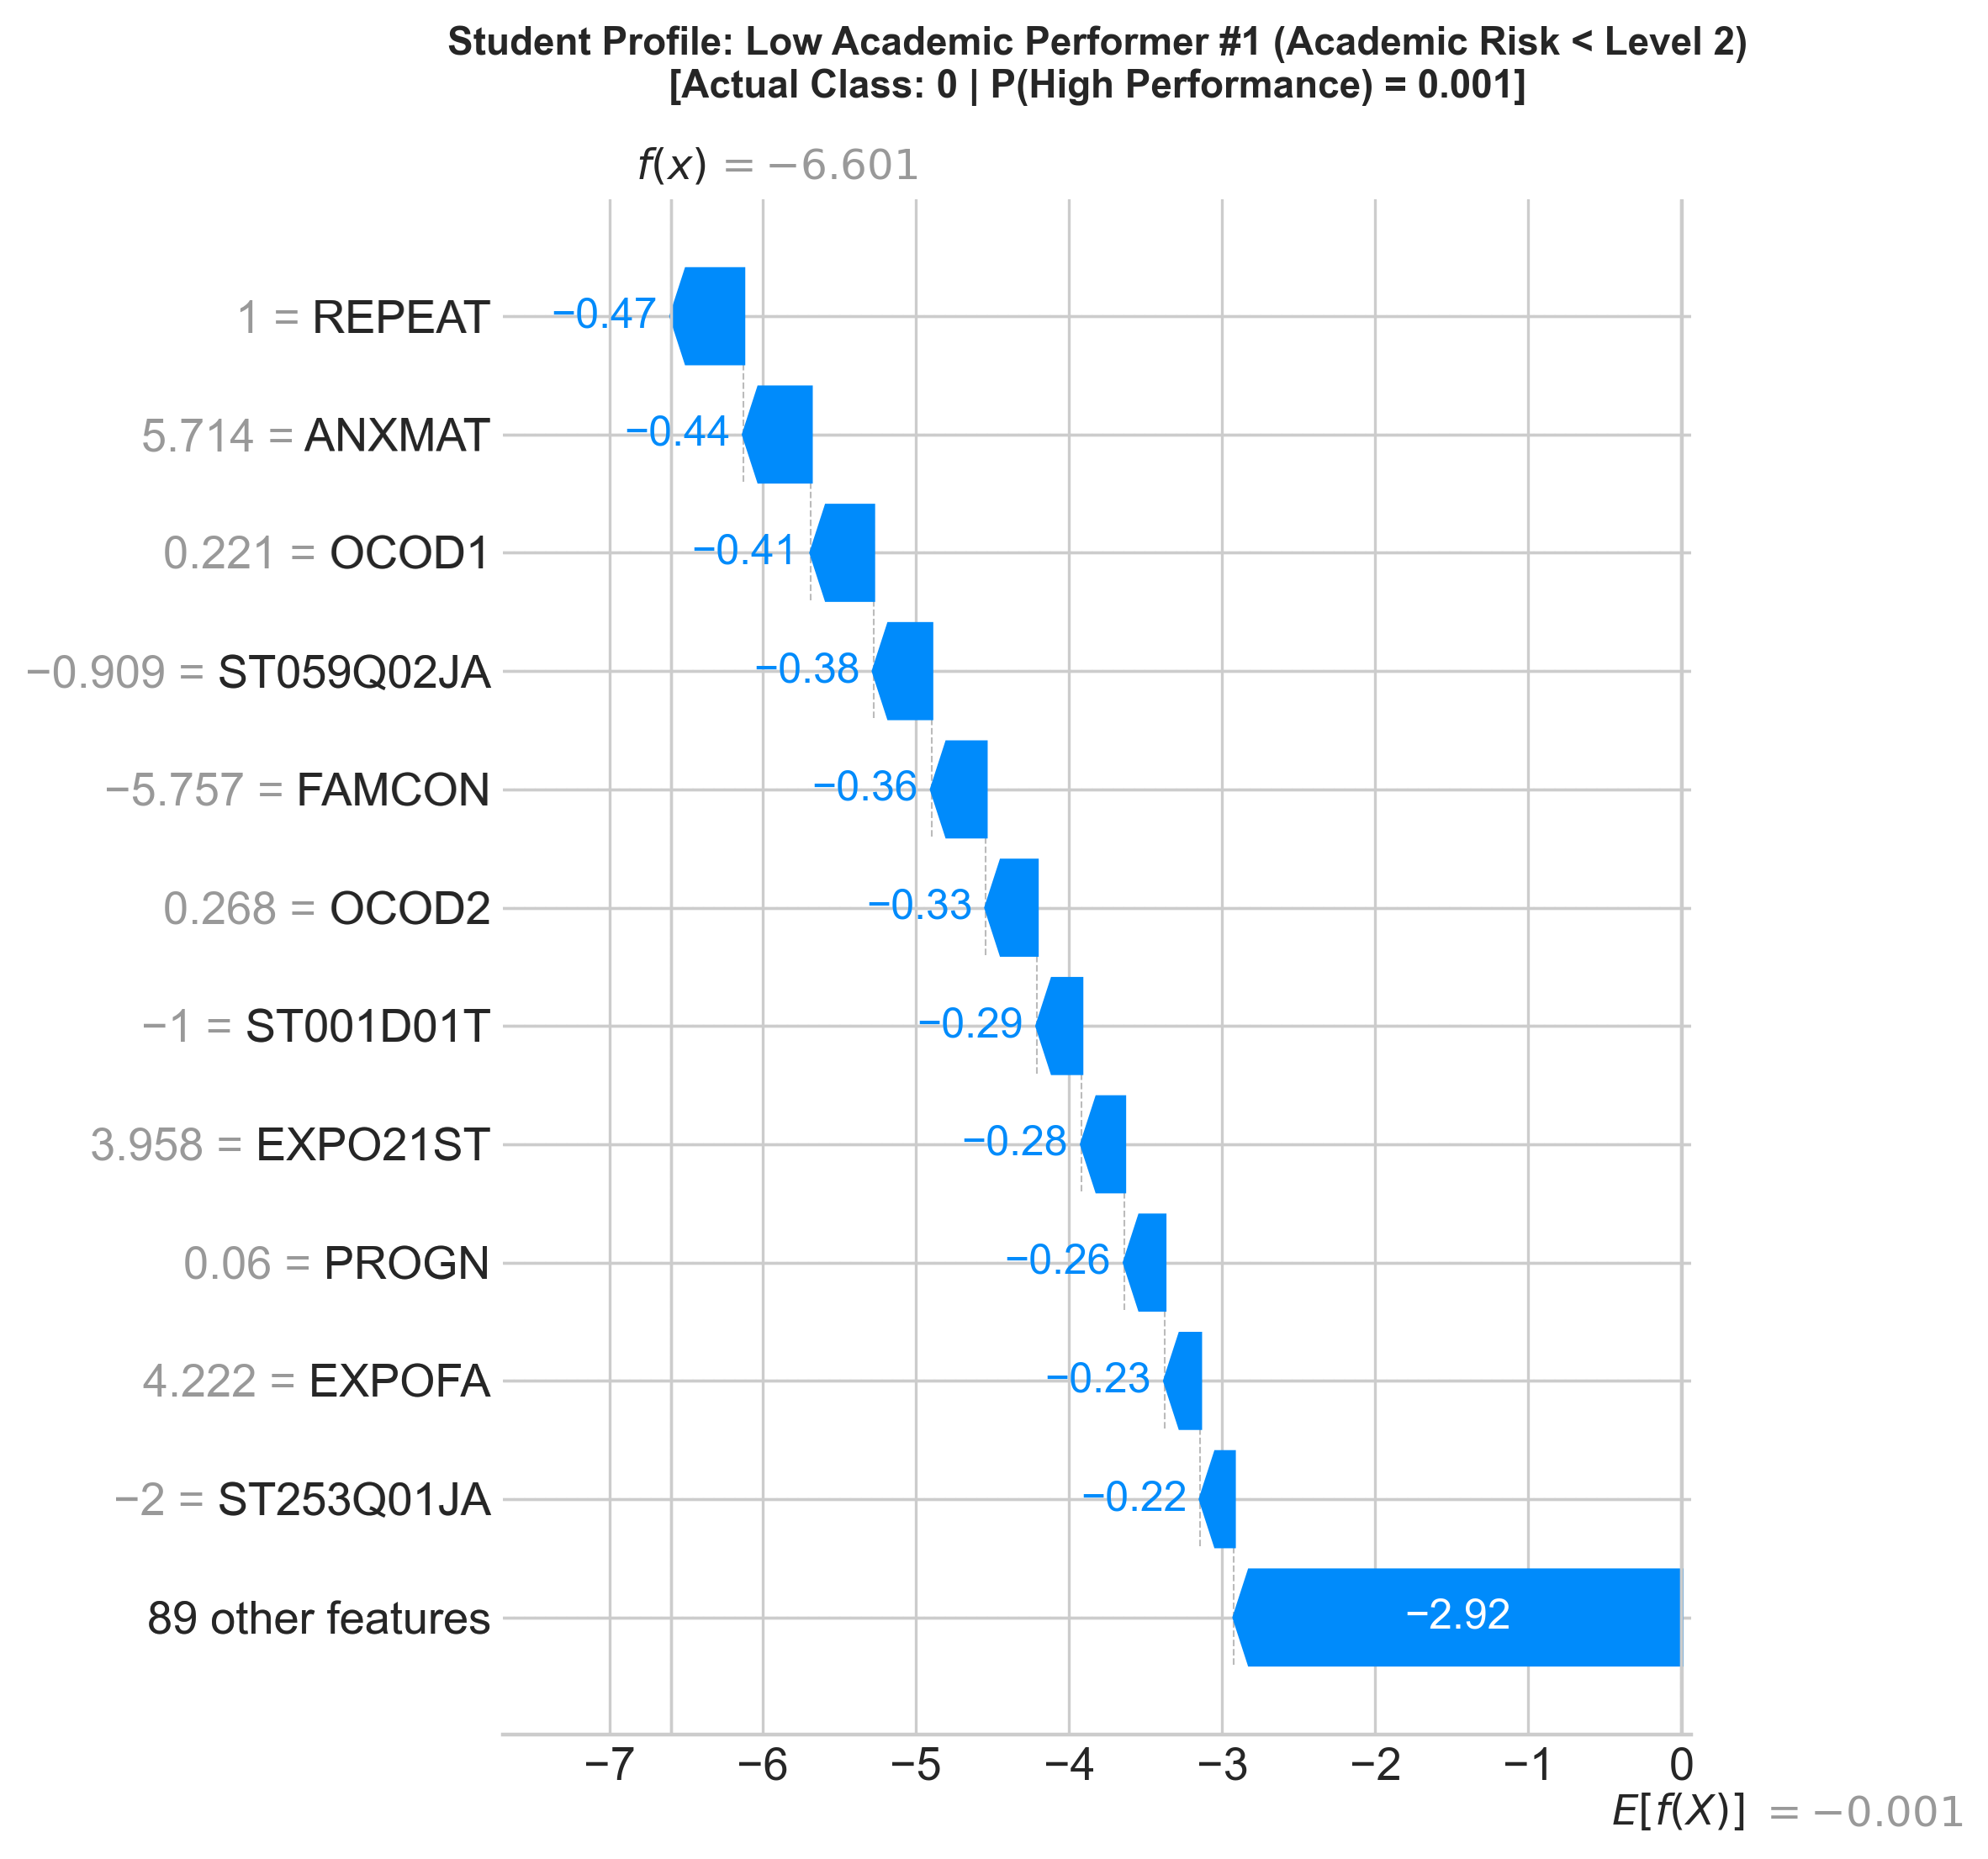


CONTRASTIVE CASE 2B: Low Performer Alternative Profile (Academic Risk < Level 2)


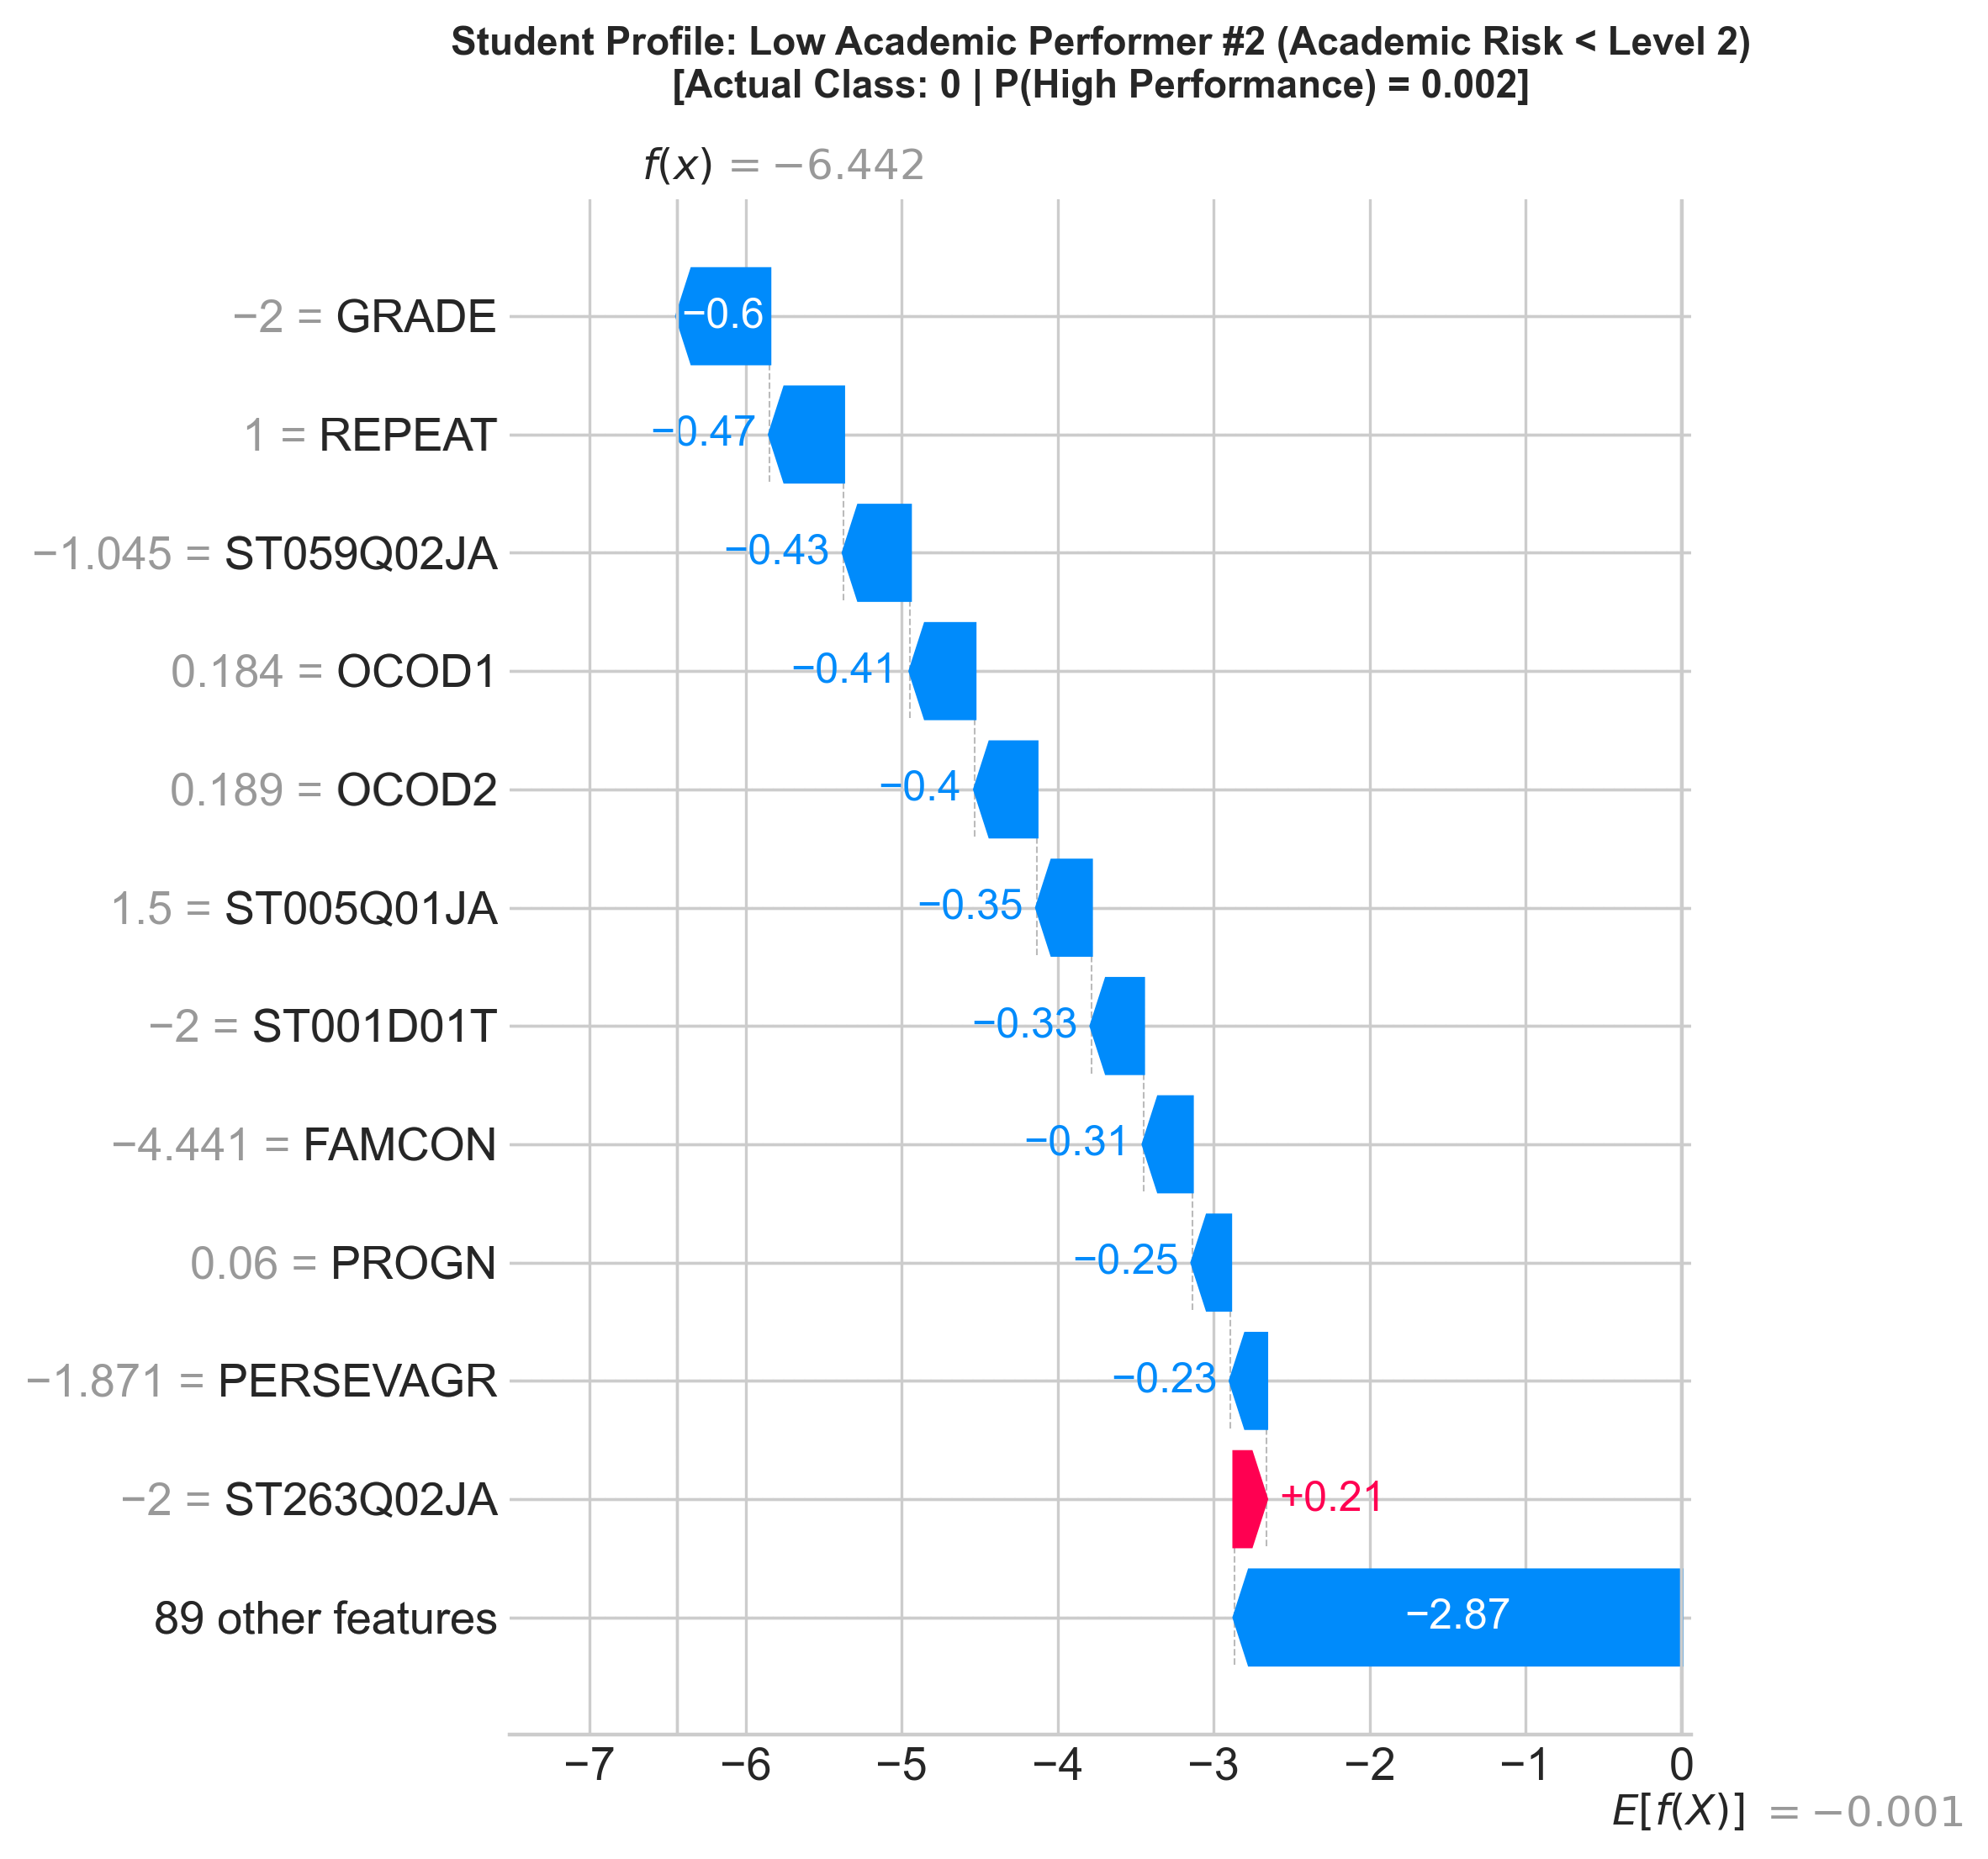

In [9]:
import shap
import matplotlib.pyplot as plt
from IPython.display import Image, display
from src.evaluation.explainability import (
    compute_shap_explanations,
    plot_shap_summary,
    plot_shap_global_importance,
    plot_shap_waterfall_cases,
)
from src.data.metadata_explorer import PISAMetadataExplorer

best_model_name = "XGBoost (TabRep Balanced)" if xgb_bal is not None else "XGBoost (Unbalanced)"
best_xgb_model = xgb_bal if xgb_bal is not None else xgb_unbal
best_y_prob = y_prob_xgb2 if xgb_bal is not None else y_prob_xgb1

print(f"Explaining top model: {best_model_name}")
explainer, shap_values = compute_shap_explanations(best_xgb_model, X_test)

# Global Beeswarm Plot
plt.figure(figsize=(10, 8), dpi=120)
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title(f"SHAP Beeswarm: Top Drivers of Academic Performance ({best_model_name})", fontsize=12, fontweight="bold", pad=14)
plt.tight_layout()
plt.show()

# Global Mean |SHAP| Bar Plot
plt.figure(figsize=(9, 6), dpi=120)
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title("Global Feature Importance (Mean |SHAP Value|)", fontsize=12, fontweight="bold", pad=14)
plt.tight_layout()
plt.show()

# Attribution Summary Table with Official OECD Metadata Labels
if "explorer" not in locals():
    explorer = PISAMetadataExplorer()

def get_clean_label(feature_name: str) -> str:
    var_info = explorer.get_variable(feature_name)
    if var_info and "label" in var_info:
        return var_info["label"].replace("\ufffd", "'").strip()
    return "N/A"

mean_abs_shap = np.abs(shap_values.values).mean(axis=0)
shap_summary_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean |SHAP| Attribution": mean_abs_shap
}).sort_values("Mean |SHAP| Attribution", ascending=False)
shap_summary_df["PISA 2022 Description / Label"] = shap_summary_df["Feature"].apply(get_clean_label)

top_shap_table = shap_summary_df.head(15)[["Feature", "PISA 2022 Description / Label", "Mean |SHAP| Attribution"]].reset_index(drop=True).copy()

print("\n--- Global Feature Attribution: Top 15 SHAP Influence Drivers ---")
display(
    top_shap_table.style.format({"Mean |SHAP| Attribution": "{:.4f}"})
      .bar(subset=["Mean |SHAP| Attribution"], color="#4a90e2", vmin=0)
      .set_properties(subset=["PISA 2022 Description / Label"], **{"text-align": "left"})
)

# Contrastive Individual Student Waterfall Plots (Profiles of High vs Low Academic Performance)
cases = plot_shap_waterfall_cases(
    shap_values=shap_values,
    y_true=y_test.values,
    y_pred_prob=best_y_prob,
    output_dir="outputs/figures",
    max_display=12
)

print("\n--- Contrastive Student Waterfall Explanations Saved ---")
for case_id, path in cases.items():
    print(f" - {case_id}: {path}")

print("\n" + "="*80)
print("CONTRASTIVE CASE 1A: Confident High Performer (Proficiency >= Level 2)")
print("="*80)
display(Image(filename=str(cases.get("high_performer_case_1", "outputs/figures/shap_waterfall_high_performer_case_1.png"))))

print("\n" + "="*80)
print("CONTRASTIVE CASE 1B: High Performer Alternative Profile (Proficiency >= Level 2)")
print("="*80)
display(Image(filename=str(cases.get("high_performer_case_2", "outputs/figures/shap_waterfall_high_performer_case_2.png"))))

print("\n" + "="*80)
print("CONTRASTIVE CASE 2A: Confident Low Performer (Academic Risk < Level 2)")
print("="*80)
display(Image(filename=str(cases.get("low_performer_case_1", "outputs/figures/shap_waterfall_low_performer_case_1.png"))))

print("\n" + "="*80)
print("CONTRASTIVE CASE 2B: Low Performer Alternative Profile (Academic Risk < Level 2)")
print("="*80)
display(Image(filename=str(cases.get("low_performer_case_2", "outputs/figures/shap_waterfall_low_performer_case_2.png"))))


### Model Interpretability and Feature Attribution via SHAP

SHAP decomposition of the balanced XGBoost model provides game-theoretic attributions for individual predictors, quantifying both global importance and sample-level decision trajectories:

1. **Parental Occupation and Educational Background:** Parental occupational codes represent the strongest global drivers in the model, led by maternal occupation (`OCOD1`, mean $|\text{SHAP}| = 0.3812$) and paternal occupation (`OCOD2`, 0.2530), along with maternal educational attainment (`ST005Q01JA`, 0.1997). As shown in the beeswarm distribution, higher occupational prestige scores consistently shift log-odds in favor of Level 2 proficiency, illustrating the empirical footprint of intergenerational capital transmission.

2. **Cognitive Affect and Mindset Factors:** Subject-specific self-efficacy (`MATHEFF`, 0.2117) demonstrates broad horizontal attribution spread. High self-efficacy acts as a protective factor, contributing substantial positive log-odds. Conversely, the fixed mindset indicator (`ST263Q02JA`, 0.1639: agreement that intelligence cannot be changed substantially) carries negative attribution values, consistent with psychological literature on mindset and academic resilience.

3. **Instructional Time as a Direct Educational Lever:** Total weekly instructional periods across all subjects (`ST059Q02JA`, 0.2113) ranks among the top five attributions. Unlike family background characteristics, classroom hours represent an institutional parameter that can be influenced directly by curriculum planning and school administration.

4. **Digital Resources and Extracurricular Habits:** Access to dedicated learning devices such as tablets or e-readers (`IC171Q03JA`, 0.2767) and total household digital screens (`ST253Q01JA`, 0.1723) positively differentiate students with technological support. Regular morning exercise before school (`ST294Q05JA`, 0.1741) also contributes modest positive attributions, correlating structured morning routines with academic readiness.

5. **Local Prediction Archetypes (Waterfall Analysis):**
   - *High-Performing Students:* Individual waterfalls (Cases 1 and 2, $P \ge 0.998$) illustrate how strong parental occupational capital, elevated mathematics self-efficacy (`MATHEFF` $> 4.8$), and favorable instructional hours collectively elevate predictions well above the base value ($E[f(x)] = -0.001$).
   - *Students at Academic Risk:* Profiles exhibiting severe underperformance (Cases 1 and 2, $P \le 0.002$) reveal distinct compounding risk mechanisms. In Case 1, grade repetition (`REPEAT` = 1, $-0.47$), acute mathematics anxiety (`ANXMAT` = 5.71, $-0.44$), and low instructional hours (`ST059Q02JA`, $-0.38$) depress the log-odds ($f(x) = -6.60$). In Case 2, modal grade delay (`GRADE` = -2, $-0.60$), grade repetition (`REPEAT` = 1, $-0.47$), and a severe shortage of instructional periods ($-0.43$) drive the outcome ($f(x) = -6.44$). These contrastive profiles highlight specific multidimensional risk factors that early-warning institutional systems can track.
